In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [1]:
import os
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

device = "cuda" if torch.cuda.is_available() else "cpu"

# ============================================================
# 1️⃣ Load saved multimodal features
# ============================================================
import pickle
with open("/content/drive/MyDrive/DemetiaPitt/multimodal_features.pkl", "rb") as f:
    X, y = pickle.load(f)

X = np.array(X)
y = np.array(y)

print("Feature matrix:", X.shape)
TEXT_DIM, AUDIO_DIM = 768, 768  # Each modality's embedding dimension

# Sanity check
assert X.shape[1] == TEXT_DIM + AUDIO_DIM, f"Expected {TEXT_DIM + AUDIO_DIM}, got {X.shape[1]}"

# ============================================================
# 2️⃣ Train/Val/Test Split
# ============================================================
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)

# Split each modality
X_text_train = torch.tensor(X_train[:, :TEXT_DIM]).float()
X_audio_train = torch.tensor(X_train[:, TEXT_DIM:]).float()
y_train_t = torch.tensor(y_train).float()

X_text_val = torch.tensor(X_val[:, :TEXT_DIM]).float()
X_audio_val = torch.tensor(X_val[:, TEXT_DIM:]).float()
y_val_t = torch.tensor(y_val).float()

X_text_test = torch.tensor(X_test[:, :TEXT_DIM]).float()
X_audio_test = torch.tensor(X_test[:, TEXT_DIM:]).float()
y_test_t = torch.tensor(y_test).float()

train_ds = TensorDataset(X_text_train, X_audio_train, y_train_t)
val_ds = TensorDataset(X_text_val, X_audio_val, y_val_t)
test_ds = TensorDataset(X_text_test, X_audio_test, y_test_t)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=32)
test_loader = DataLoader(test_ds, batch_size=32)

# ============================================================
# 3️⃣ Cross-Attention Fusion Model
# ============================================================
class FusionAttention(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.attn = nn.MultiheadAttention(embed_dim=dim, num_heads=8, dropout=0.2, batch_first=True)
        self.norm = nn.LayerNorm(dim)

    def forward(self, text, audio):
        # Add sequence dimension
        text = text.unsqueeze(1)
        audio = audio.unsqueeze(1)
        # text attends to audio (Q=text, K=V=audio)
        attn_out, _ = self.attn(text, audio, audio)
        out = self.norm(attn_out + text)  # Residual connection
        return out.squeeze(1)

class AlzheimerCrossAttentionModel(nn.Module):
    def __init__(self, text_dim, audio_dim):
        super().__init__()
        fusion_dim = min(text_dim, audio_dim)
        self.text_proj = nn.Linear(text_dim, fusion_dim)
        self.audio_proj = nn.Linear(audio_dim, fusion_dim)
        self.cross_attn = FusionAttention(fusion_dim)

        self.classifier = nn.Sequential(
            nn.Linear(fusion_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 1)
        )

    def forward(self, text, audio):
        t_proj = self.text_proj(text)
        a_proj = self.audio_proj(audio)
        fused = self.cross_attn(t_proj, a_proj)
        out = self.classifier(fused)
        return out

# ============================================================
# 4️⃣ Train Model
# ============================================================
model = AlzheimerCrossAttentionModel(TEXT_DIM, AUDIO_DIM).to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

for epoch in range(20):
    model.train()
    total_loss = 0
    for t_batch, a_batch, yb in train_loader:
        t_batch, a_batch, yb = t_batch.to(device), a_batch.to(device), yb.to(device)
        preds = model(t_batch, a_batch).squeeze()
        loss = criterion(preds, yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    # Validation
    model.eval()
    val_loss = 0
    with torch.no_grad():
        for t_batch, a_batch, yb in val_loader:
            t_batch, a_batch, yb = t_batch.to(device), a_batch.to(device), yb.to(device)
            preds = model(t_batch, a_batch).squeeze()
            val_loss += criterion(preds, yb).item()

    print(f"Epoch {epoch+1:02d}: Train Loss={total_loss/len(train_loader):.4f} | Val Loss={val_loss/len(val_loader):.4f}")

# ============================================================
# 5️⃣ Evaluation
# ============================================================
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for t_batch, a_batch, yb in test_loader:
        t_batch, a_batch = t_batch.to(device), a_batch.to(device)
        preds = torch.sigmoid(model(t_batch, a_batch).squeeze()).cpu().numpy()
        all_preds.extend((preds > 0.5).astype(int))
        all_labels.extend(yb.numpy())

print("\n✅ Confusion Matrix:")
print(confusion_matrix(all_labels, all_preds))
print("\n✅ Classification Report:")
print(classification_report(all_labels, all_preds, target_names=["Control", "Dementia"]))


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/DemetiaPitt/multimodal_features.pkl'

In [ ]:
torch.save(model.state_dict(), "cross_attention_model.pth")
print("Model saved successfully.")


Model saved successfully.


In [ ]:
model = AlzheimerCrossAttentionModel(TEXT_DIM, AUDIO_DIM)
model.load_state_dict(torch.load("cross_attention_model.pth"))
model.eval()


AlzheimerCrossAttentionModel(
  (text_proj): Linear(in_features=768, out_features=768, bias=True)
  (audio_proj): Linear(in_features=768, out_features=768, bias=True)
  (cross_attn): FusionAttention(
    (attn): MultiheadAttention(
      (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
    )
    (norm): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
  )
  (classifier): Sequential(
    (0): Linear(in_features=768, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=128, out_features=1, bias=True)
  )
)

In [ ]:
!pip install transformers torchaudio librosa scikit-learn pyclan


ERROR: Could not find a version that satisfies the requirement pyclan (from versions: none)
ERROR: No matching distribution found for pyclan


In [ ]:
import os
import torch
import torchaudio
import numpy as np
from tqdm import tqdm
from transformers import (
    DistilBertTokenizer, DistilBertModel,
    Wav2Vec2Processor, Wav2Vec2Model
)

# Paths (update according to your Drive structure)
TEXT_DIR = "/content/drive/MyDrive/DemetiaPitt/pitt/"
AUDIO_DIR = "/content/drive/MyDrive/DemetiaPitt/pitt_corpus/"
OUTPUT_DIR = "/content/drive/MyDrive/DemetiaPitt/features3/"
os.makedirs(OUTPUT_DIR, exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"

# Load models
tokenizer = DistilBertTokenizer.from_pretrained("distilbert-base-uncased")
text_model = DistilBertModel.from_pretrained("distilbert-base-uncased").to(device)
audio_processor = Wav2Vec2Processor.from_pretrained("facebook/wav2vec2-base-960h")
audio_model = Wav2Vec2Model.from_pretrained("facebook/wav2vec2-base-960h").to(device)

def collect_files(label):
    """Collect all paired .cha and .mp3 files."""
    files = []
    for task in ["cookie", "fluency", "sentence"]:
        text_path = os.path.join(TEXT_DIR, label, task)
        audio_path = os.path.join(AUDIO_DIR, label, task)
        if not os.path.exists(text_path) or not os.path.exists(audio_path):
            continue
        for fname in os.listdir(text_path):
            if fname.endswith(".cha"):
                cha_file = os.path.join(text_path, fname)
                mp3_file = os.path.join(audio_path, fname.replace(".cha", ".mp3"))
                if os.path.exists(mp3_file):
                    files.append((cha_file, mp3_file, label))
    return files

def extract_features(cha_path, mp3_path):
    """Extract fused text + audio embedding."""
    # --- TEXT ---
    try:
        with open(cha_path, "r", encoding="utf-8", errors="ignore") as f:
            lines = f.readlines()
        utterances = [line for line in lines if line.startswith("*PAR:")]
        text = " ".join([line.split(":", 1)[1].strip() for line in utterances])
        if not text.strip():
            raise ValueError("Empty text")
        tokens = tokenizer(text, return_tensors="pt", truncation=True, padding=True).to(device)
        with torch.no_grad():
            text_embed = text_model(**tokens).last_hidden_state.mean(dim=1).squeeze()
    except Exception as e:
        print(f"Text processing failed for {cha_path}: {e}")
        return None

    # --- AUDIO ---
    try:
        waveform, sr = torchaudio.load(mp3_path)
        waveform = waveform.mean(dim=0)  # Convert stereo → mono
        if sr != 16000:
            waveform = torchaudio.transforms.Resample(sr, 16000)(waveform)
        waveform = waveform[:16000 * 30]  # Trim to 30 seconds
        inputs = audio_processor(waveform, sampling_rate=16000, return_tensors="pt").to(device)
        with torch.no_grad():
            audio_embed = audio_model(**inputs).last_hidden_state.mean(dim=1).squeeze()
    except Exception as e:
        print(f"Audio processing failed for {mp3_path}: {e}")
        return None

    # --- FUSION ---
    return torch.cat([text_embed, audio_embed], dim=0).cpu().numpy()

# --- MAIN LOOP ---
all_files = collect_files("control") + collect_files("dementia")
print(f"Total files to process: {len(all_files)}")

for cha_path, mp3_path, label in tqdm(all_files):
    try:
        fused_feat = extract_features(cha_path, mp3_path)
        if fused_feat is not None:
            name = os.path.splitext(os.path.basename(cha_path))[0]
            np.save(os.path.join(OUTPUT_DIR, f"{label}_{name}.npy"), fused_feat)
    except Exception as e:
        print(f"❌ Failed on {cha_path}: {e}")


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/85.0 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/378M [00:00<?, ?B/s]

Some weights of Wav2Vec2Model were not initialized from the model checkpoint at facebook/wav2vec2-base-960h and are newly initialized: ['masked_spec_embed']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Total files to process: 822


  0%|          | 0/822 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/torchaudio/_backend/utils.py:213: UserWarning: In 2.9, this function's implementation will be changed to use torchaudio.load_with_torchcodec` under the hood. Some parameters like ``normalize``, ``format``, ``buffer_size``, and ``backend`` will be ignored. We recommend that you port your code to rely directly on TorchCodec's decoder instead: https://docs.pytorch.org/torchcodec/stable/generated/torchcodec.decoders.AudioDecoder.html#torchcodec.decoders.AudioDecoder.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchaudio/_backend/ffmpeg.py:88: UserWarning: torio.io._streaming_media_decoder.StreamingMediaDecoder has been deprecated. This deprecation is part of a large refactoring effort to transition TorchAudio into a maintenance phase. The decoding and encoding capabilities of PyTorch for both audio and video are being consolidated into TorchCodec. Please see https://github.com/pytorch/audio/issues/

In [ ]:
import os
import numpy as np

FEATURE_DIR = "/content/drive/MyDrive/DemetiaPitt/features3/"
X, y = [], []

for file in os.listdir(FEATURE_DIR):
    if file.endswith(".npy"):
        path = os.path.join(FEATURE_DIR, file)
        features = np.load(path)
        label = 1 if "dementia" in file else 0  # 1 = dementia, 0 = control
        X.append(features)
        y.append(label)

X = np.array(X)
y = np.array(y)

print("Feature matrix shape:", X.shape)
print("Labels distribution:", np.bincount(y))


Feature matrix shape: (551, 1536)
Labels distribution: [243 308]


In [ ]:
import pickle
from sklearn.model_selection import train_test_split

# Save combined dataset for reuse
with open("/content/drive/MyDrive/DemetiaPitt/multimodal_features45.pkl", "wb") as f:
    pickle.dump((X, y), f)




In [ ]:
import os
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

device = "cuda" if torch.cuda.is_available() else "cpu"

# ============================================================
# 1️⃣ Load saved multimodal features
# ============================================================
import pickle
with open("/content/drive/MyDrive/DemetiaPitt/multimodal_features45.pkl", "rb") as f:
    X, y = pickle.load(f)

X = np.array(X)
y = np.array(y)

print("Feature matrix:", X.shape)
TEXT_DIM, AUDIO_DIM = 768, 768  # Each modality's embedding dimension

# Sanity check
assert X.shape[1] == TEXT_DIM + AUDIO_DIM, f"Expected {TEXT_DIM + AUDIO_DIM}, got {X.shape[1]}"

# ============================================================
# 2️⃣ Train/Val/Test Split
# ============================================================
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)

# Split each modality
X_text_train = torch.tensor(X_train[:, :TEXT_DIM]).float()
X_audio_train = torch.tensor(X_train[:, TEXT_DIM:]).float()
y_train_t = torch.tensor(y_train).float()

X_text_val = torch.tensor(X_val[:, :TEXT_DIM]).float()
X_audio_val = torch.tensor(X_val[:, TEXT_DIM:]).float()
y_val_t = torch.tensor(y_val).float()

X_text_test = torch.tensor(X_test[:, :TEXT_DIM]).float()
X_audio_test = torch.tensor(X_test[:, TEXT_DIM:]).float()
y_test_t = torch.tensor(y_test).float()

train_ds = TensorDataset(X_text_train, X_audio_train, y_train_t)
val_ds = TensorDataset(X_text_val, X_audio_val, y_val_t)
test_ds = TensorDataset(X_text_test, X_audio_test, y_test_t)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=32)
test_loader = DataLoader(test_ds, batch_size=32)

# ============================================================
# 3️⃣ Cross-Attention Fusion Model
# ============================================================
class FusionAttention(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.attn = nn.MultiheadAttention(embed_dim=dim, num_heads=8, dropout=0.2, batch_first=True)
        self.norm = nn.LayerNorm(dim)

    def forward(self, text, audio):
        # Add sequence dimension
        text = text.unsqueeze(1)
        audio = audio.unsqueeze(1)
        # text attends to audio (Q=text, K=V=audio)
        attn_out, _ = self.attn(text, audio, audio)
        out = self.norm(attn_out + text)  # Residual connection
        return out.squeeze(1)

class AlzheimerCrossAttentionModel(nn.Module):
    def __init__(self, text_dim, audio_dim):
        super().__init__()
        fusion_dim = min(text_dim, audio_dim)
        self.text_proj = nn.Linear(text_dim, fusion_dim)
        self.audio_proj = nn.Linear(audio_dim, fusion_dim)
        self.cross_attn = FusionAttention(fusion_dim)

        self.classifier = nn.Sequential(
            nn.Linear(fusion_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 1)
        )

    def forward(self, text, audio):
        t_proj = self.text_proj(text)
        a_proj = self.audio_proj(audio)
        fused = self.cross_attn(t_proj, a_proj)
        out = self.classifier(fused)
        return out

# ============================================================
# 4️⃣ Train Model
# ============================================================
model = AlzheimerCrossAttentionModel(TEXT_DIM, AUDIO_DIM).to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

for epoch in range(20):
    model.train()
    total_loss = 0
    for t_batch, a_batch, yb in train_loader:
        t_batch, a_batch, yb = t_batch.to(device), a_batch.to(device), yb.to(device)
        preds = model(t_batch, a_batch).squeeze()
        loss = criterion(preds, yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    # Validation
    model.eval()
    val_loss = 0
    with torch.no_grad():
        for t_batch, a_batch, yb in val_loader:
            t_batch, a_batch, yb = t_batch.to(device), a_batch.to(device), yb.to(device)
            preds = model(t_batch, a_batch).squeeze()
            val_loss += criterion(preds, yb).item()

    print(f"Epoch {epoch+1:02d}: Train Loss={total_loss/len(train_loader):.4f} | Val Loss={val_loss/len(val_loader):.4f}")

# ============================================================
# 5️⃣ Evaluation
# ============================================================
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for t_batch, a_batch, yb in test_loader:
        t_batch, a_batch = t_batch.to(device), a_batch.to(device)
        preds = torch.sigmoid(model(t_batch, a_batch).squeeze()).cpu().numpy()
        all_preds.extend((preds > 0.5).astype(int))
        all_labels.extend(yb.numpy())

print("\n✅ Confusion Matrix:")
print(confusion_matrix(all_labels, all_preds))
print("\n✅ Classification Report:")
print(classification_report(all_labels, all_preds, target_names=["Control", "Dementia"]))


Feature matrix: (551, 1536)
Epoch 01: Train Loss=0.6231 | Val Loss=0.5406
Epoch 02: Train Loss=0.4694 | Val Loss=0.3590
Epoch 03: Train Loss=0.3428 | Val Loss=0.2865
Epoch 04: Train Loss=0.2909 | Val Loss=0.3169
Epoch 05: Train Loss=0.3072 | Val Loss=0.2456
Epoch 06: Train Loss=0.2952 | Val Loss=0.2741
Epoch 07: Train Loss=0.2722 | Val Loss=0.2245
Epoch 08: Train Loss=0.2550 | Val Loss=0.2118
Epoch 09: Train Loss=0.2469 | Val Loss=0.2017
Epoch 10: Train Loss=0.2260 | Val Loss=0.1908
Epoch 11: Train Loss=0.2182 | Val Loss=0.1877
Epoch 12: Train Loss=0.2108 | Val Loss=0.1790
Epoch 13: Train Loss=0.1922 | Val Loss=0.1622
Epoch 14: Train Loss=0.1672 | Val Loss=0.1585
Epoch 15: Train Loss=0.2001 | Val Loss=0.3010
Epoch 16: Train Loss=0.2704 | Val Loss=0.1977
Epoch 17: Train Loss=0.1742 | Val Loss=0.1608
Epoch 18: Train Loss=0.1673 | Val Loss=0.1435
Epoch 19: Train Loss=0.1457 | Val Loss=0.1468
Epoch 20: Train Loss=0.1386 | Val Loss=0.1612

✅ Confusion Matrix:
[[20  5]
 [ 1 30]]

✅ Classific

In [ ]:
import os
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

device = "cuda" if torch.cuda.is_available() else "cpu"

# ============================================================
# 1️⃣ Load saved multimodal features
# ============================================================
import pickle
with open("/content/drive/MyDrive/DemetiaPitt/multimodal_features.pkl", "rb") as f:
    X, y = pickle.load(f)

X = np.array(X)
y = np.array(y)

print("Feature matrix:", X.shape)
TEXT_DIM, AUDIO_DIM = 768, 768  # Each modality's embedding dimension

# Sanity check
assert X.shape[1] == TEXT_DIM + AUDIO_DIM, f"Expected {TEXT_DIM + AUDIO_DIM}, got {X.shape[1]}"

# ============================================================
# 2️⃣ Train/Val/Test Split
# ============================================================
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)

# Split each modality
X_text_train = torch.tensor(X_train[:, :TEXT_DIM]).float()
X_audio_train = torch.tensor(X_train[:, TEXT_DIM:]).float()
y_train_t = torch.tensor(y_train).float()

X_text_val = torch.tensor(X_val[:, :TEXT_DIM]).float()
X_audio_val = torch.tensor(X_val[:, TEXT_DIM:]).float()
y_val_t = torch.tensor(y_val).float()

X_text_test = torch.tensor(X_test[:, :TEXT_DIM]).float()
X_audio_test = torch.tensor(X_test[:, TEXT_DIM:]).float()
y_test_t = torch.tensor(y_test).float()

train_ds = TensorDataset(X_text_train, X_audio_train, y_train_t)
val_ds = TensorDataset(X_text_val, X_audio_val, y_val_t)
test_ds = TensorDataset(X_text_test, X_audio_test, y_test_t)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=32)
test_loader = DataLoader(test_ds, batch_size=32)

# ============================================================
# 3️⃣ Cross-Attention Fusion Model
# ============================================================
class FusionAttention(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.attn = nn.MultiheadAttention(embed_dim=dim, num_heads=8, dropout=0.2, batch_first=True)
        self.norm = nn.LayerNorm(dim)

    def forward(self, text, audio):
        # Add sequence dimension
        text = text.unsqueeze(1)
        audio = audio.unsqueeze(1)
        # text attends to audio (Q=text, K=V=audio)
        attn_out, _ = self.attn(text, audio, audio)
        out = self.norm(attn_out + text)  # Residual connection
        return out.squeeze(1)

class AlzheimerCrossAttentionModel(nn.Module):
    def __init__(self, text_dim, audio_dim):
        super().__init__()
        fusion_dim = min(text_dim, audio_dim)
        self.text_proj = nn.Linear(text_dim, fusion_dim)
        self.audio_proj = nn.Linear(audio_dim, fusion_dim)
        self.cross_attn = FusionAttention(fusion_dim)

        self.classifier = nn.Sequential(
            nn.Linear(fusion_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 1)
        )

    def forward(self, text, audio):
        t_proj = self.text_proj(text)
        a_proj = self.audio_proj(audio)
        fused = self.cross_attn(t_proj, a_proj)
        out = self.classifier(fused)
        return out

# ============================================================
# 4️⃣ Train Model
# ============================================================
model = AlzheimerCrossAttentionModel(TEXT_DIM, AUDIO_DIM).to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

for epoch in range(20):
    model.train()
    total_loss = 0
    for t_batch, a_batch, yb in train_loader:
        t_batch, a_batch, yb = t_batch.to(device), a_batch.to(device), yb.to(device)
        preds = model(t_batch, a_batch).squeeze()
        loss = criterion(preds, yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    # Validation
    model.eval()
    val_loss = 0
    with torch.no_grad():
        for t_batch, a_batch, yb in val_loader:
            t_batch, a_batch, yb = t_batch.to(device), a_batch.to(device), yb.to(device)
            preds = model(t_batch, a_batch).squeeze()
            val_loss += criterion(preds, yb).item()

    print(f"Epoch {epoch+1:02d}: Train Loss={total_loss/len(train_loader):.4f} | Val Loss={val_loss/len(val_loader):.4f}")

# ============================================================
# 5️⃣ Evaluation
# ============================================================
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for t_batch, a_batch, yb in test_loader:
        t_batch, a_batch = t_batch.to(device), a_batch.to(device)
        preds = torch.sigmoid(model(t_batch, a_batch).squeeze()).cpu().numpy()
        all_preds.extend((preds > 0.5).astype(int))
        all_labels.extend(yb.numpy())

print("\n✅ Confusion Matrix:")
print(confusion_matrix(all_labels, all_preds))
print("\n✅ Classification Report:")
print(classification_report(all_labels, all_preds, target_names=["Control", "Dementia"]))


Feature matrix: (551, 1536)
Epoch 01: Train Loss=0.6282 | Val Loss=0.5409
Epoch 02: Train Loss=0.4540 | Val Loss=0.3591
Epoch 03: Train Loss=0.3398 | Val Loss=0.3067
Epoch 04: Train Loss=0.3054 | Val Loss=0.3062
Epoch 05: Train Loss=0.2845 | Val Loss=0.2397
Epoch 06: Train Loss=0.2671 | Val Loss=0.2216
Epoch 07: Train Loss=0.2383 | Val Loss=0.2303
Epoch 08: Train Loss=0.2673 | Val Loss=0.2973
Epoch 09: Train Loss=0.2260 | Val Loss=0.1830
Epoch 10: Train Loss=0.2370 | Val Loss=0.2289
Epoch 11: Train Loss=0.2126 | Val Loss=0.2084
Epoch 12: Train Loss=0.1990 | Val Loss=0.2133
Epoch 13: Train Loss=0.2084 | Val Loss=0.1728
Epoch 14: Train Loss=0.1867 | Val Loss=0.1955
Epoch 15: Train Loss=0.1786 | Val Loss=0.1658
Epoch 16: Train Loss=0.1696 | Val Loss=0.1612
Epoch 17: Train Loss=0.1526 | Val Loss=0.1597
Epoch 18: Train Loss=0.1494 | Val Loss=0.1691
Epoch 19: Train Loss=0.1738 | Val Loss=0.1729
Epoch 20: Train Loss=0.1512 | Val Loss=0.1933

✅ Confusion Matrix:
[[21  4]
 [ 0 31]]

✅ Classific

In [ ]:
import torch
import numpy as np
import pickle
from sklearn.metrics import confusion_matrix, classification_report

# Device
device = "cuda" if torch.cuda.is_available() else "cpu"

# Load data (same preprocessing as before)
with open("/content/drive/MyDrive/DemetiaPitt/multimodal_features.pkl", "rb") as f:
    X, y = pickle.load(f)

TEXT_DIM, AUDIO_DIM = 768, 768
X = np.array(X)
y = np.array(y)

# Train/Val/Test split (same random_state)
from sklearn.model_selection import train_test_split
seed = 42
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, stratify=y, random_state=seed)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=seed)

import torch
X_text_test = torch.tensor(X_test[:, :TEXT_DIM]).float()
X_audio_test = torch.tensor(X_test[:, TEXT_DIM:]).float()
y_test_t = torch.tensor(y_test).float()

test_loader = torch.utils.data.DataLoader(
    torch.utils.data.TensorDataset(X_text_test, X_audio_test, y_test_t),
    batch_size=32
)


class FusionAttention(torch.nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.attn = torch.nn.MultiheadAttention(embed_dim=dim, num_heads=8, dropout=0.2, batch_first=True)
        self.norm = torch.nn.LayerNorm(dim)

    def forward(self, text, audio):
        text = text.unsqueeze(1)
        audio = audio.unsqueeze(1)
        attn_out, _ = self.attn(text, audio, audio)
        out = self.norm(attn_out + text)
        return out.squeeze(1)

class AlzheimerCrossAttentionModel(torch.nn.Module):
    def __init__(self, text_dim, audio_dim):
        super().__init__()
        fusion_dim = min(text_dim, audio_dim)
        self.text_proj = torch.nn.Linear(text_dim, fusion_dim)
        self.audio_proj = torch.nn.Linear(audio_dim, fusion_dim)
        self.cross_attn = FusionAttention(fusion_dim)
        self.classifier = torch.nn.Sequential(
            torch.nn.Linear(fusion_dim, 256),
            torch.nn.ReLU(),
            torch.nn.Dropout(0.3),
            torch.nn.Linear(256, 128),
            torch.nn.ReLU(),
            torch.nn.Dropout(0.3),
            torch.nn.Linear(128, 1)
        )

    def forward(self, text, audio):
        t_proj = self.text_proj(text)
        a_proj = self.audio_proj(audio)
        fused = self.cross_attn(t_proj, a_proj)
        out = self.classifier(fused)
        return out

# ============================================================
# 3️⃣ Load the saved weights
# ============================================================
model = AlzheimerCrossAttentionModel(TEXT_DIM, AUDIO_DIM).to(device)
model.load_state_dict(torch.load("cross_attention_model.pth", map_location=device))
model.eval()

# ============================================================
# 4️⃣ Evaluate accuracy on test set
# ============================================================
all_preds, all_labels = [], []
with torch.no_grad():
    for t_batch, a_batch, yb in test_loader:
        t_batch, a_batch = t_batch.to(device), a_batch.to(device)
        preds = torch.sigmoid(model(t_batch, a_batch).squeeze()).cpu().numpy()
        all_preds.extend((preds > 0.5).astype(int))
        all_labels.extend(yb.numpy())

print("\n✅ Confusion Matrix:")
print(confusion_matrix(all_labels, all_preds))
print("\n✅ Classification Report:")
print(classification_report(all_labels, all_preds, target_names=["Control", "Dementia"]))



✅ Confusion Matrix:
[[24  1]
 [ 1 30]]

✅ Classification Report:
              precision    recall  f1-score   support

     Control       0.96      0.96      0.96        25
    Dementia       0.97      0.97      0.97        31

    accuracy                           0.96        56
   macro avg       0.96      0.96      0.96        56
weighted avg       0.96      0.96      0.96        56



In [ ]:
model = AlzheimerCrossAttentionModel(TEXT_DIM, AUDIO_DIM).to(device)
model.load_state_dict(torch.load("cross_attention_model.pth"))
model.eval()

# Evaluate on test data
all_preds, all_labels = [], []
with torch.no_grad():
    for t_batch, a_batch, yb in test_loader:
        t_batch, a_batch = t_batch.to(device), a_batch.to(device)
        preds = torch.sigmoid(model(t_batch, a_batch).squeeze()).cpu().numpy()
        all_preds.extend((preds > 0.5).astype(int))
        all_labels.extend(yb.numpy())

print(confusion_matrix(all_labels, all_preds))
print(classification_report(all_labels, all_preds, target_names=["Control", "Dementia"]))


[[24  1]
 [ 1 30]]
              precision    recall  f1-score   support

     Control       0.96      0.96      0.96        25
    Dementia       0.97      0.97      0.97        31

    accuracy                           0.96        56
   macro avg       0.96      0.96      0.96        56
weighted avg       0.96      0.96      0.96        56



In [ ]:
# ============================================================
# Multimodal Alzheimer Detection - Cross-Attention Model (Reproducible)
# ============================================================

import os
import numpy as np
import random
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import pickle

# ============================================================
# 1️⃣ Make Results Fully Reproducible
# ============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

# ============================================================
# 2️⃣ Load Saved Multimodal Features
# ============================================================
with open("/content/drive/MyDrive/DemetiaPitt/multimodal_features.pkl", "rb") as f:
    X, y = pickle.load(f)

X = np.array(X)
y = np.array(y)
TEXT_DIM, AUDIO_DIM = 768, 768

assert X.shape[1] == TEXT_DIM + AUDIO_DIM, f"Expected {TEXT_DIM + AUDIO_DIM}, got {X.shape[1]}"
print("✅ Feature matrix shape:", X.shape)

# ============================================================
# 3️⃣ Train/Val/Test Split (deterministic)
# ============================================================
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)

# Convert to Tensors
X_text_train = torch.tensor(X_train[:, :TEXT_DIM]).float()
X_audio_train = torch.tensor(X_train[:, TEXT_DIM:]).float()
y_train_t = torch.tensor(y_train).float()

X_text_val = torch.tensor(X_val[:, :TEXT_DIM]).float()
X_audio_val = torch.tensor(X_val[:, TEXT_DIM:]).float()
y_val_t = torch.tensor(y_val).float()

X_text_test = torch.tensor(X_test[:, :TEXT_DIM]).float()
X_audio_test = torch.tensor(X_test[:, TEXT_DIM:]).float()
y_test_t = torch.tensor(y_test).float()

train_ds = TensorDataset(X_text_train, X_audio_train, y_train_t)
val_ds = TensorDataset(X_text_val, X_audio_val, y_val_t)
test_ds = TensorDataset(X_text_test, X_audio_test, y_test_t)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=32)
test_loader = DataLoader(test_ds, batch_size=32)

# ============================================================
# 4️⃣ Define Cross-Attention Fusion Model
# ============================================================
class FusionAttention(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.attn = nn.MultiheadAttention(embed_dim=dim, num_heads=8, dropout=0.2, batch_first=True)
        self.norm = nn.LayerNorm(dim)

    def forward(self, text, audio):
        text = text.unsqueeze(1)
        audio = audio.unsqueeze(1)
        attn_out, _ = self.attn(text, audio, audio)
        out = self.norm(attn_out + text)
        return out.squeeze(1)

class AlzheimerCrossAttentionModel(nn.Module):
    def __init__(self, text_dim, audio_dim):
        super().__init__()
        fusion_dim = min(text_dim, audio_dim)
        self.text_proj = nn.Linear(text_dim, fusion_dim)
        self.audio_proj = nn.Linear(audio_dim, fusion_dim)
        self.cross_attn = FusionAttention(fusion_dim)
        self.classifier = nn.Sequential(
            nn.Linear(fusion_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 1)
        )

    def forward(self, text, audio):
        t_proj = self.text_proj(text)
        a_proj = self.audio_proj(audio)
        fused = self.cross_attn(t_proj, a_proj)
        out = self.classifier(fused)
        return out

# ============================================================
# 5️⃣ Train the Model
# ============================================================
model = AlzheimerCrossAttentionModel(TEXT_DIM, AUDIO_DIM).to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

best_val_loss = float("inf")

for epoch in range(20):
    model.train()
    total_loss = 0
    for t_batch, a_batch, yb in train_loader:
        t_batch, a_batch, yb = t_batch.to(device), a_batch.to(device), yb.to(device)
        preds = model(t_batch, a_batch).squeeze()
        loss = criterion(preds, yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    # Validation
    model.eval()
    val_loss = 0
    with torch.no_grad():
        for t_batch, a_batch, yb in val_loader:
            t_batch, a_batch, yb = t_batch.to(device), a_batch.to(device), yb.to(device)
            preds = model(t_batch, a_batch).squeeze()
            val_loss += criterion(preds, yb).item()

    avg_train_loss = total_loss / len(train_loader)
    avg_val_loss = val_loss / len(val_loader)
    print(f"Epoch {epoch+1:02d} | Train Loss={avg_train_loss:.4f} | Val Loss={avg_val_loss:.4f}")

    # Save best model
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        torch.save({
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
        }, "/content/drive/MyDrive/DemetiaPitt/best_model.pth")

print("\n✅ Training completed successfully!")

# ============================================================
# 6️⃣ Evaluation on Test Set
# ============================================================
checkpoint = torch.load("/content/drive/MyDrive/DemetiaPitt/best_model.pth", map_location=device)
model.load_state_dict(checkpoint['model_state_dict'])
optimizer.load_state_dict(checkpoint['optimizer_state_dict'])

model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for t_batch, a_batch, yb in test_loader:
        t_batch, a_batch = t_batch.to(device), a_batch.to(device)
        preds = torch.sigmoid(model(t_batch, a_batch).squeeze()).cpu().numpy()
        all_preds.extend((preds > 0.5).astype(int))
        all_labels.extend(yb.numpy())

print("\n✅ Confusion Matrix:")
print(confusion_matrix(all_labels, all_preds))
print("\n✅ Classification Report:")
print(classification_report(all_labels, all_preds, target_names=["Control", "Dementia"]))


Using device: cuda
✅ Feature matrix shape: (551, 1536)
Epoch 01 | Train Loss=0.6323 | Val Loss=0.5397
Epoch 02 | Train Loss=0.4727 | Val Loss=0.3627
Epoch 03 | Train Loss=0.3525 | Val Loss=0.2842
Epoch 04 | Train Loss=0.3074 | Val Loss=0.2837
Epoch 05 | Train Loss=0.2865 | Val Loss=0.2347
Epoch 06 | Train Loss=0.2557 | Val Loss=0.2264
Epoch 07 | Train Loss=0.2593 | Val Loss=0.2211
Epoch 08 | Train Loss=0.2626 | Val Loss=0.1896
Epoch 09 | Train Loss=0.2379 | Val Loss=0.1780
Epoch 10 | Train Loss=0.2122 | Val Loss=0.1641
Epoch 11 | Train Loss=0.2173 | Val Loss=0.1935
Epoch 12 | Train Loss=0.2561 | Val Loss=0.1767
Epoch 13 | Train Loss=0.1992 | Val Loss=0.1995
Epoch 14 | Train Loss=0.2164 | Val Loss=0.1831
Epoch 15 | Train Loss=0.1860 | Val Loss=0.1399
Epoch 16 | Train Loss=0.1717 | Val Loss=0.1680
Epoch 17 | Train Loss=0.1640 | Val Loss=0.1314
Epoch 18 | Train Loss=0.1466 | Val Loss=0.1447
Epoch 19 | Train Loss=0.1316 | Val Loss=0.1306
Epoch 20 | Train Loss=0.1523 | Val Loss=0.2557

✅ Tr

In [ ]:
# ============================================================
# Multimodal Alzheimer Detection - Cross-Attention Model (Reproducible)
# ============================================================

import os
import numpy as np
import random
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import pickle

# ============================================================
# 1️⃣ Make Results Fully Reproducible
# ============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

# ============================================================
# 2️⃣ Load Saved Multimodal Features
# ============================================================
with open("/content/drive/MyDrive/DemetiaPitt/multimodal_features.pkl", "rb") as f:
    X, y = pickle.load(f)

X = np.array(X)
y = np.array(y)
TEXT_DIM, AUDIO_DIM = 768, 768

assert X.shape[1] == TEXT_DIM + AUDIO_DIM, f"Expected {TEXT_DIM + AUDIO_DIM}, got {X.shape[1]}"
print("✅ Feature matrix shape:", X.shape)

# ============================================================
# 3️⃣ Train/Val/Test Split (deterministic)
# ============================================================
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)

# Convert to Tensors
X_text_train = torch.tensor(X_train[:, :TEXT_DIM]).float()
X_audio_train = torch.tensor(X_train[:, TEXT_DIM:]).float()
y_train_t = torch.tensor(y_train).float()

X_text_val = torch.tensor(X_val[:, :TEXT_DIM]).float()
X_audio_val = torch.tensor(X_val[:, TEXT_DIM:]).float()
y_val_t = torch.tensor(y_val).float()

X_text_test = torch.tensor(X_test[:, :TEXT_DIM]).float()
X_audio_test = torch.tensor(X_test[:, TEXT_DIM:]).float()
y_test_t = torch.tensor(y_test).float()

train_ds = TensorDataset(X_text_train, X_audio_train, y_train_t)
val_ds = TensorDataset(X_text_val, X_audio_val, y_val_t)
test_ds = TensorDataset(X_text_test, X_audio_test, y_test_t)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=32)
test_loader = DataLoader(test_ds, batch_size=32)

# ============================================================
# 4️⃣ Define Cross-Attention Fusion Model
# ============================================================
class FusionAttention(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.attn = nn.MultiheadAttention(embed_dim=dim, num_heads=8, dropout=0.2, batch_first=True)
        self.norm = nn.LayerNorm(dim)

    def forward(self, text, audio):
        text = text.unsqueeze(1)
        audio = audio.unsqueeze(1)
        attn_out, _ = self.attn(text, audio, audio)
        out = self.norm(attn_out + text)
        return out.squeeze(1)

class AlzheimerCrossAttentionModel(nn.Module):
    def __init__(self, text_dim, audio_dim):
        super().__init__()
        fusion_dim = min(text_dim, audio_dim)
        self.text_proj = nn.Linear(text_dim, fusion_dim)
        self.audio_proj = nn.Linear(audio_dim, fusion_dim)
        self.cross_attn = FusionAttention(fusion_dim)
        self.classifier = nn.Sequential(
            nn.Linear(fusion_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 1)
        )

    def forward(self, text, audio):
        t_proj = self.text_proj(text)
        a_proj = self.audio_proj(audio)
        fused = self.cross_attn(t_proj, a_proj)
        out = self.classifier(fused)
        return out

# ============================================================
# 5️⃣ Train the Model
# ============================================================
model = AlzheimerCrossAttentionModel(TEXT_DIM, AUDIO_DIM).to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

best_val_loss = float("inf")

for epoch in range(20):
    model.train()
    total_loss = 0
    for t_batch, a_batch, yb in train_loader:
        t_batch, a_batch, yb = t_batch.to(device), a_batch.to(device), yb.to(device)
        preds = model(t_batch, a_batch).squeeze()
        loss = criterion(preds, yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    # Validation
    model.eval()
    val_loss = 0
    with torch.no_grad():
        for t_batch, a_batch, yb in val_loader:
            t_batch, a_batch, yb = t_batch.to(device), a_batch.to(device), yb.to(device)
            preds = model(t_batch, a_batch).squeeze()
            val_loss += criterion(preds, yb).item()

    avg_train_loss = total_loss / len(train_loader)
    avg_val_loss = val_loss / len(val_loader)
    print(f"Epoch {epoch+1:02d} | Train Loss={avg_train_loss:.4f} | Val Loss={avg_val_loss:.4f}")

    # Save best model
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        torch.save({
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
        }, "/content/drive/MyDrive/best_model.pth")

print("\n✅ Training completed successfully!")

# ============================================================
# 6️⃣ Evaluation on Test Set
# ============================================================
checkpoint = torch.load("/content/drive/MyDrive/best_model.pth", map_location=device)
model.load_state_dict(checkpoint['model_state_dict'])
optimizer.load_state_dict(checkpoint['optimizer_state_dict'])

model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for t_batch, a_batch, yb in test_loader:
        t_batch, a_batch = t_batch.to(device), a_batch.to(device)
        preds = torch.sigmoid(model(t_batch, a_batch).squeeze()).cpu().numpy()
        all_preds.extend((preds > 0.5).astype(int))
        all_labels.extend(yb.numpy())

print("\n✅ Confusion Matrix:")
print(confusion_matrix(all_labels, all_preds))
print("\n✅ Classification Report:")
print(classification_report(all_labels, all_preds, target_names=["Control", "Dementia"]))


Using device: cuda
✅ Feature matrix shape: (551, 1536)
Epoch 01 | Train Loss=0.6323 | Val Loss=0.5397
Epoch 02 | Train Loss=0.4727 | Val Loss=0.3627
Epoch 03 | Train Loss=0.3525 | Val Loss=0.2842
Epoch 04 | Train Loss=0.3074 | Val Loss=0.2837
Epoch 05 | Train Loss=0.2865 | Val Loss=0.2347
Epoch 06 | Train Loss=0.2557 | Val Loss=0.2264
Epoch 07 | Train Loss=0.2593 | Val Loss=0.2211
Epoch 08 | Train Loss=0.2626 | Val Loss=0.1896
Epoch 09 | Train Loss=0.2379 | Val Loss=0.1780
Epoch 10 | Train Loss=0.2122 | Val Loss=0.1641
Epoch 11 | Train Loss=0.2173 | Val Loss=0.1935
Epoch 12 | Train Loss=0.2561 | Val Loss=0.1767
Epoch 13 | Train Loss=0.1992 | Val Loss=0.1995
Epoch 14 | Train Loss=0.2164 | Val Loss=0.1831
Epoch 15 | Train Loss=0.1860 | Val Loss=0.1399
Epoch 16 | Train Loss=0.1717 | Val Loss=0.1680
Epoch 17 | Train Loss=0.1640 | Val Loss=0.1314
Epoch 18 | Train Loss=0.1466 | Val Loss=0.1447
Epoch 19 | Train Loss=0.1316 | Val Loss=0.1306
Epoch 20 | Train Loss=0.1523 | Val Loss=0.2557

✅ Tr

In [ ]:
import os
import torch
import torchaudio
import numpy as np
from tqdm import tqdm
from transformers import DistilBertTokenizer, DistilBertModel, Wav2Vec2Processor, Wav2Vec2Model

# ── Paths ──────────────────────────────────────────────────────────────────────
TEXT_DIR   = "/content/drive/MyDrive/ADReSS_IS2020/transcription"
AUDIO_DIR  = "/content/drive/MyDrive/ADReSS_IS2020/audio"
OUTPUT_DIR = "/content/drive/MyDrive/features_test"
os.makedirs(OUTPUT_DIR, exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

# ── Verify paths exist before doing anything ───────────────────────────────────
for path, name in [(TEXT_DIR, "TEXT_DIR"), (AUDIO_DIR, "AUDIO_DIR")]:
    if not os.path.exists(path):
        raise FileNotFoundError(f"{name} not found: {path}")
    print(f"{name} contents: {os.listdir(path)}")

# ── Load models ────────────────────────────────────────────────────────────────
print("Loading DistilBERT...")
tokenizer  = DistilBertTokenizer.from_pretrained("distilbert-base-uncased")
text_model = DistilBertModel.from_pretrained("distilbert-base-uncased").to(device)
text_model.eval()

print("Loading Wav2Vec2...")
audio_processor = Wav2Vec2Processor.from_pretrained("facebook/wav2vec2-base-960h")
audio_model     = Wav2Vec2Model.from_pretrained("facebook/wav2vec2-base-960h").to(device)
audio_model.eval()

# ── Collect files ──────────────────────────────────────────────────────────────
def collect_files(label_folder):
    """
    Collects matched .cha and .mp3 pairs from the given subfolder.
    label_folder: 'cc' (control) or 'cd' (dementia)
    """
    files = []
    text_path  = os.path.join(TEXT_DIR, label_folder)
    audio_path = os.path.join(AUDIO_DIR, label_folder)

    # FIX 1: Check subfolders actually exist before listing
    if not os.path.exists(text_path):
        print(f"WARNING: text subfolder not found: {text_path}")
        return files
    if not os.path.exists(audio_path):
        print(f"WARNING: audio subfolder not found: {audio_path}")
        return files

    for fname in os.listdir(text_path):
        if fname.endswith(".cha"):
            cha_file = os.path.join(text_path, fname)
            # FIX 2: Try both .mp3 and .wav extensions
            mp3_file = os.path.join(audio_path, fname.replace(".cha", ".mp3"))
            wav_file = os.path.join(audio_path, fname.replace(".cha", ".wav"))

            if os.path.exists(mp3_file):
                files.append((cha_file, mp3_file, label_folder))
            elif os.path.exists(wav_file):
                files.append((cha_file, wav_file, label_folder))
            else:
                print(f"WARNING: No audio found for {fname}")
    return files

# ── Feature extraction ─────────────────────────────────────────────────────────
def extract_text_features(cha_path):
    """Extract DistilBERT embeddings from .cha transcript."""
    with open(cha_path, "r", encoding="utf-8", errors="ignore") as f:
        lines = f.readlines()

    # FIX 3: Extract participant lines only (filter noise/headers)
    utterances = [
        line.split(":", 1)[1].strip()
        for line in lines
        if line.startswith("*PAR:")
    ]

    if not utterances:
        print(f"WARNING: No *PAR: lines found in {cha_path}")
        return None

    text = " ".join(utterances)

    # FIX 4: Handle empty text after joining
    if not text.strip():
        print(f"WARNING: Empty text after parsing {cha_path}")
        return None

    tokens = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=512,       # FIX 5: Explicit max_length for DistilBERT
        padding=True
    ).to(device)

    with torch.no_grad():
        output = text_model(**tokens)

    # Mean pool over token dimension → shape (768,)
    embed = output.last_hidden_state.mean(dim=1).squeeze(0)
    return embed


def extract_audio_features(mp3_path):
    """Extract Wav2Vec2 embeddings from audio file."""
    waveform, sr = torchaudio.load(mp3_path)

    # FIX 6: Convert stereo to mono correctly
    if waveform.shape[0] > 1:
        waveform = waveform.mean(dim=0, keepdim=True)
    waveform = waveform.squeeze(0)  # shape: (samples,)

    # Resample to 16kHz if needed
    if sr != 16000:
        resampler = torchaudio.transforms.Resample(orig_freq=sr, new_freq=16000)
        waveform  = resampler(waveform)

    # FIX 7: Clip to 30 seconds max to avoid OOM
    max_samples = 16000 * 30
    waveform = waveform[:max_samples]

    # FIX 8: Wav2Vec2Processor expects a plain numpy array, not a tensor
    inputs = audio_processor(
        waveform.numpy(),
        sampling_rate=16000,
        return_tensors="pt",
        padding=True
    )
    # Move input_values to device manually (processor output isn't on device)
    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        output = audio_model(**inputs)

    # Mean pool over time dimension → shape (768,)
    embed = output.last_hidden_state.mean(dim=1).squeeze(0)
    return embed


def extract_features(cha_path, mp3_path):
    """Fuse text and audio embeddings into one feature vector."""
    try:
        text_embed = extract_text_features(cha_path)
    except Exception as e:
        print(f"Text extraction failed for {cha_path}: {e}")
        return None

    try:
        audio_embed = extract_audio_features(mp3_path)
    except Exception as e:
        print(f"Audio extraction failed for {mp3_path}: {e}")
        return None

    if text_embed is None or audio_embed is None:
        return None

    # FIX 9: Move both to CPU before concatenating
    fused = torch.cat([text_embed.cpu(), audio_embed.cpu()], dim=0)
    return fused.numpy()  # shape: (768 + 768,) = (1536,)

# ── Main pipeline ──────────────────────────────────────────────────────────────
cc_files = collect_files("cc")
cd_files = collect_files("cd")
all_files = cc_files + cd_files

print(f"\nFound {len(cc_files)} control (cc) files")
print(f"Found {len(cd_files)} dementia (cd) files")
print(f"Total: {len(all_files)} files\n")

if len(all_files) == 0:
    raise RuntimeError(
        "No files found! Check your folder structure. "
        f"TEXT_DIR contents: {os.listdir(TEXT_DIR)}"
    )

skipped = 0
saved   = 0

for cha_path, mp3_path, label in tqdm(all_files, desc="Extracting features"):
    name = os.path.splitext(os.path.basename(cha_path))[0]
    out_path = os.path.join(OUTPUT_DIR, f"{label}_{name}.npy")

    # FIX 10: Skip already-processed files (useful if run is interrupted)
    if os.path.exists(out_path):
        saved += 1
        continue

    fused_feat = extract_features(cha_path, mp3_path)

    if fused_feat is not None:
        np.save(out_path, fused_feat)
        saved += 1
    else:
        skipped += 1

print(f"\nDone! Saved: {saved} | Skipped/Failed: {skipped}")
print(f"Output shape of each feature: (1536,)  [768 text + 768 audio]")

Using device: cuda
TEXT_DIR contents: ['cd', 'cc']
AUDIO_DIR contents: ['cd', 'cc']
Loading DistilBERT...


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading Wav2Vec2...


Loading weights:   0%|          | 0/210 [00:00<?, ?it/s]

Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base-960h
Key               | Status     | 
------------------+------------+-
lm_head.bias      | UNEXPECTED | 
lm_head.weight    | UNEXPECTED | 
masked_spec_embed | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Found 49 control (cc) files
Found 0 dementia (cd) files
Total: 49 files



Extracting features: 100%|██████████| 49/49 [01:04<00:00,  1.33s/it]


Done! Saved: 49 | Skipped/Failed: 0
Output shape of each feature: (1536,)  [768 text + 768 audio]


Using device: cuda
✅ Model loaded successfully
Found 49 feature files
Control (cc): 49 | Dementia (cd): 0

           EVALUATION RESULTS

📊 Confusion Matrix:
[[48  1]
 [ 0  0]]

📋 Classification Report:
               precision    recall  f1-score   support

 Control (cc)     1.0000    0.9796    0.9897        49
Dementia (cd)     0.0000    0.0000    0.0000         0

     accuracy                         0.9796        49
    macro avg     0.5000    0.4898    0.4948        49
 weighted avg     1.0000    0.9796    0.9897        49

⚠️  Only one class in test set — AUC not computed
✅ Overall Accuracy: 97.96%


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


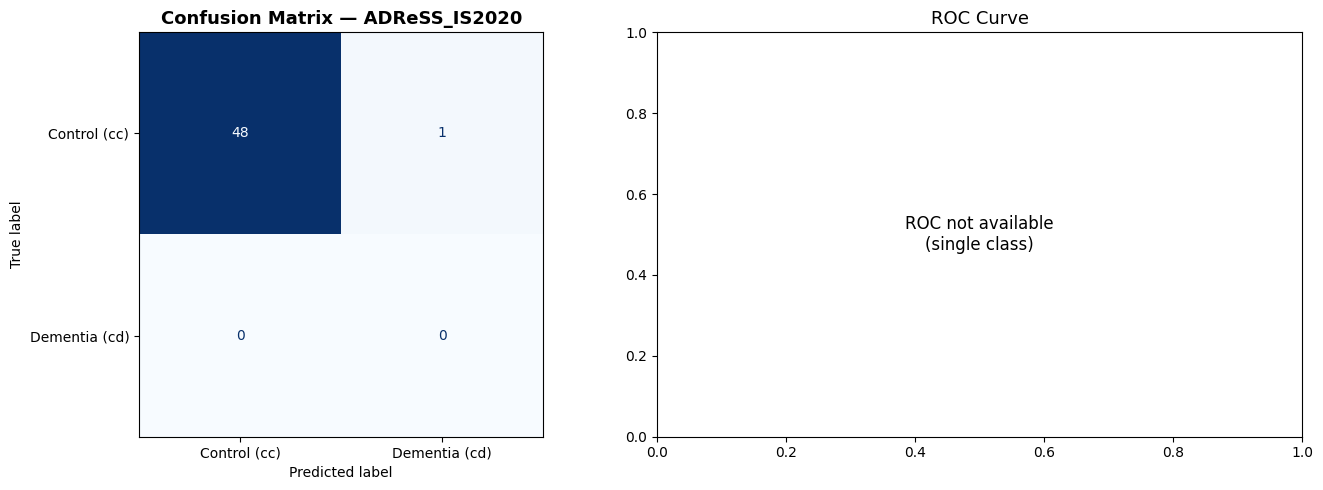


📁 Plot saved to Google Drive

📄 Per-file Predictions (first 20):
Filename                              True   Pred     Prob  Match
-----------------------------------------------------------------
cc_S011.npy                             cc     cc   0.0416      ✓
cc_S019.npy                             cc     cc   0.0568      ✓
cc_S002.npy                             cc     cc   0.0259      ✓
cc_S020.npy                             cc     cc   0.0433      ✓
cc_S004.npy                             cc     cc   0.0779      ✓
cc_S015.npy                             cc     cc   0.0191      ✓
cc_S009.npy                             cc     cc   0.0242      ✓
cc_S005.npy                             cc     cc   0.0540      ✓
cc_S012.npy                             cc     cc   0.0228      ✓
cc_S007.npy                             cc     cc   0.0270      ✓
cc_S017.npy                             cc     cc   0.0684      ✓
cc_S013.npy                             cc     cc   0.2293      ✓
cc_S018.np

In [ ]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix, classification_report,
    ConfusionMatrixDisplay, roc_auc_score, roc_curve
)

# ── Config ─────────────────────────────────────────────────────────────────────
TEXT_DIM   = 768
AUDIO_DIM  = 768
OUTPUT_DIR = "/content/drive/MyDrive/features_test"   # FIX 1: was missing
MODEL_PATH = "/content/drive/MyDrive/95%_accuracy_trainedmodel.pth"
device     = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

# ── Model Architecture ─────────────────────────────────────────────────────────
class FusionAttention(torch.nn.Module):
    def __init__(self, dim):
        super().__init__()
        # FIX 2: num_heads must divide dim evenly — 768/8=96 ✓
        self.attn = torch.nn.MultiheadAttention(
            embed_dim=dim, num_heads=8, dropout=0.2, batch_first=True
        )
        self.norm = torch.nn.LayerNorm(dim)

    def forward(self, text, audio):
        text  = text.unsqueeze(1)
        audio = audio.unsqueeze(1)
        attn_out, _ = self.attn(text, audio, audio)
        return self.norm(attn_out + text).squeeze(1)


class AlzheimerCrossAttentionModel(torch.nn.Module):
    def __init__(self, text_dim, audio_dim):
        super().__init__()
        fusion_dim = min(text_dim, audio_dim)  # 768
        self.text_proj  = torch.nn.Linear(text_dim, fusion_dim)
        self.audio_proj = torch.nn.Linear(audio_dim, fusion_dim)
        self.cross_attn = FusionAttention(fusion_dim)
        self.classifier = torch.nn.Sequential(
            torch.nn.Linear(fusion_dim, 256),
            torch.nn.ReLU(),
            torch.nn.Dropout(0.3),
            torch.nn.Linear(256, 128),
            torch.nn.ReLU(),
            torch.nn.Dropout(0.3),
            torch.nn.Linear(128, 1)
        )

    def forward(self, text, audio):
        t_proj = self.text_proj(text)
        a_proj = self.audio_proj(audio)
        fused  = self.cross_attn(t_proj, a_proj)
        return self.classifier(fused)

# ── Load Model ─────────────────────────────────────────────────────────────────
model = AlzheimerCrossAttentionModel(TEXT_DIM, AUDIO_DIM).to(device)

# FIX 3: Handle both raw state_dict and checkpoint dict formats
checkpoint = torch.load(MODEL_PATH, map_location=device)
if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    model.load_state_dict(checkpoint["model_state_dict"])
else:
    model.load_state_dict(checkpoint)

model.eval()
print("✅ Model loaded successfully")

# ── Load Features ──────────────────────────────────────────────────────────────
X_test, y_test, fnames = [], [], []

# FIX 4: Verify OUTPUT_DIR exists
if not os.path.exists(OUTPUT_DIR):
    raise FileNotFoundError(f"OUTPUT_DIR not found: {OUTPUT_DIR}")

npy_files = [f for f in os.listdir(OUTPUT_DIR) if f.endswith(".npy")]
if len(npy_files) == 0:
    raise RuntimeError(f"No .npy files found in {OUTPUT_DIR}")

print(f"Found {len(npy_files)} feature files")

for fname in npy_files:
    feat = np.load(os.path.join(OUTPUT_DIR, fname))

    # FIX 5: Validate feature dimension before appending
    expected_dim = TEXT_DIM + AUDIO_DIM  # 1536
    if feat.shape[0] != expected_dim:
        print(f"WARNING: Skipping {fname} — shape {feat.shape}, expected ({expected_dim},)")
        continue

    # FIX 6: More robust label parsing (handles filenames like cc_S001.npy or cd_S001.npy)
    fname_lower = fname.lower()
    if fname_lower.startswith("cc_"):
        label = 0  # Control
    elif fname_lower.startswith("cd_"):
        label = 1  # Dementia
    else:
        print(f"WARNING: Could not determine label for {fname}, skipping")
        continue

    X_test.append(feat)
    y_test.append(label)
    fnames.append(fname)

print(f"Control (cc): {y_test.count(0)} | Dementia (cd): {y_test.count(1)}")

# FIX 7: Convert to tensors properly
X_test = torch.tensor(np.array(X_test), dtype=torch.float32).to(device)
y_test = np.array(y_test)

# ── Inference ──────────────────────────────────────────────────────────────────
with torch.no_grad():
    text_feats  = X_test[:, :TEXT_DIM]
    audio_feats = X_test[:, TEXT_DIM:]

    logits  = model(text_feats, audio_feats)

    # FIX 8: Safe squeeze — handles both single sample and batch
    logits  = logits.squeeze(-1)
    probs   = torch.sigmoid(logits).cpu().numpy()

# FIX 9: Ensure probs is always 1D (edge case: single sample)
probs  = np.atleast_1d(probs)
y_pred = (probs > 0.5).astype(int)

# ── Metrics ────────────────────────────────────────────────────────────────────
print("\n" + "="*55)
print("           EVALUATION RESULTS")
print("="*55)

cm = confusion_matrix(y_test, y_pred)
print("\n📊 Confusion Matrix:")
print(cm)

print("\n📋 Classification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Control (cc)", "Dementia (cd)"],
    digits=4
))

# FIX 10: AUC only works if both classes present in y_test
if len(np.unique(y_test)) == 2:
    auc = roc_auc_score(y_test, probs)
    print(f"🎯 ROC-AUC Score: {auc:.4f}")
else:
    print("⚠️  Only one class in test set — AUC not computed")

overall_acc = np.mean(y_pred == y_test)
print(f"✅ Overall Accuracy: {overall_acc*100:.2f}%")

# ── Plots ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Confusion Matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Control (cc)", "Dementia (cd)"]
)
disp.plot(cmap=plt.cm.Blues, ax=axes[0], colorbar=False)
axes[0].set_title("Confusion Matrix — ADReSS_IS2020", fontsize=13, fontweight="bold")

# Plot 2: ROC Curve (FIX 11: only if both classes present)
if len(np.unique(y_test)) == 2:
    fpr, tpr, _ = roc_curve(y_test, probs)
    axes[1].plot(fpr, tpr, color="steelblue", lw=2, label=f"AUC = {auc:.4f}")
    axes[1].plot([0, 1], [0, 1], "k--", lw=1, label="Random")
    axes[1].set_xlabel("False Positive Rate")
    axes[1].set_ylabel("True Positive Rate")
    axes[1].set_title("ROC Curve", fontsize=13, fontweight="bold")
    axes[1].legend(loc="lower right")
    axes[1].grid(alpha=0.3)
else:
    axes[1].text(0.5, 0.5, "ROC not available\n(single class)",
                 ha="center", va="center", fontsize=12)
    axes[1].set_title("ROC Curve", fontsize=13)

plt.tight_layout()
plt.savefig("/content/drive/MyDrive/evaluation_results.png", dpi=150, bbox_inches="tight")
plt.show()
print("\n📁 Plot saved to Google Drive")

# ── Per-file Predictions (optional debug table) ────────────────────────────────
print("\n📄 Per-file Predictions (first 20):")
print(f"{'Filename':<35} {'True':>6} {'Pred':>6} {'Prob':>8} {'Match':>6}")
print("-" * 65)
for i, (fn, yt, yp, prob) in enumerate(zip(fnames, y_test, y_pred, probs)):
    if i >= 20:
        print(f"  ... and {len(fnames)-20} more")
        break
    match = "✓" if yt == yp else "✗"
    label_true = "cc" if yt == 0 else "cd"
    label_pred = "cc" if yp == 0 else "cd"
    print(f"{fn:<35} {label_true:>6} {label_pred:>6} {prob:>8.4f} {match:>6}")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# ============================================================
# Multimodal Alzheimer Detection - 5-Fold Cross Validation
# ============================================================

import os
import numpy as np
import random
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (confusion_matrix, classification_report,
                              accuracy_score, f1_score, roc_auc_score)
import pickle

# ============================================================
# 1️⃣ Make Results Fully Reproducible
# ============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

# ============================================================
# 2️⃣ Load Saved Multimodal Features
# ============================================================
with open("/content/drive/MyDrive/DemetiaPitt/multimodal_features.pkl", "rb") as f:
    X, y = pickle.load(f)

X = np.array(X)
y = np.array(y)
TEXT_DIM, AUDIO_DIM = 768, 768

assert X.shape[1] == TEXT_DIM + AUDIO_DIM, f"Expected {TEXT_DIM + AUDIO_DIM}, got {X.shape[1]}"
print("✅ Feature matrix shape:", X.shape)
print("✅ Label distribution:", np.bincount(y))

# ============================================================
# 3️⃣ Define Cross-Attention Fusion Model
# ============================================================
class FusionAttention(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.attn = nn.MultiheadAttention(embed_dim=dim, num_heads=8,
                                          dropout=0.2, batch_first=True)
        self.norm = nn.LayerNorm(dim)

    def forward(self, text, audio):
        text  = text.unsqueeze(1)
        audio = audio.unsqueeze(1)
        attn_out, _ = self.attn(text, audio, audio)
        out = self.norm(attn_out + text)
        return out.squeeze(1)


class AlzheimerCrossAttentionModel(nn.Module):
    def __init__(self, text_dim, audio_dim):
        super().__init__()
        fusion_dim = min(text_dim, audio_dim)
        self.text_proj  = nn.Linear(text_dim,  fusion_dim)
        self.audio_proj = nn.Linear(audio_dim, fusion_dim)
        self.cross_attn = FusionAttention(fusion_dim)
        self.classifier = nn.Sequential(
            nn.Linear(fusion_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 1)
        )

    def forward(self, text, audio):
        t_proj = self.text_proj(text)
        a_proj = self.audio_proj(audio)
        fused  = self.cross_attn(t_proj, a_proj)
        return self.classifier(fused)


# ============================================================
# 4️⃣ Helper — build DataLoader from numpy arrays
# ============================================================
def make_loader(X_subset, y_subset, batch_size=32, shuffle=False):
    t = torch.tensor(X_subset[:, :TEXT_DIM]).float()
    a = torch.tensor(X_subset[:, TEXT_DIM:]).float()
    lbl = torch.tensor(y_subset).float()
    ds  = TensorDataset(t, a, lbl)
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)


# ============================================================
# 5️⃣ Training Loop for ONE fold
# ============================================================
def train_one_fold(train_loader, val_loader, epochs=20):
    model     = AlzheimerCrossAttentionModel(TEXT_DIM, AUDIO_DIM).to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

    best_val_loss    = float("inf")
    best_model_state = None

    for epoch in range(epochs):
        # ---- Train ----
        model.train()
        total_loss = 0
        for t_b, a_b, yb in train_loader:
            t_b, a_b, yb = t_b.to(device), a_b.to(device), yb.to(device)
            preds = model(t_b, a_b).squeeze()
            loss  = criterion(preds, yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        # ---- Validate ----
        model.eval()
        val_loss = 0
        with torch.no_grad():
            for t_b, a_b, yb in val_loader:
                t_b, a_b, yb = t_b.to(device), a_b.to(device), yb.to(device)
                preds     = model(t_b, a_b).squeeze()
                val_loss += criterion(preds, yb).item()

        avg_train = total_loss / len(train_loader)
        avg_val   = val_loss   / len(val_loader)
        print(f"  Epoch {epoch+1:02d} | Train Loss={avg_train:.4f} | Val Loss={avg_val:.4f}")

        if avg_val < best_val_loss:
            best_val_loss    = avg_val
            best_model_state = {k: v.clone() for k, v in model.state_dict().items()}

    # Reload best weights
    model.load_state_dict(best_model_state)
    return model


# ============================================================
# 6️⃣ Evaluate ONE fold → return predictions + labels
# ============================================================
def evaluate_fold(model, test_loader):
    model.eval()
    all_preds, all_probs, all_labels = [], [], []
    with torch.no_grad():
        for t_b, a_b, yb in test_loader:
            t_b, a_b = t_b.to(device), a_b.to(device)
            probs = torch.sigmoid(model(t_b, a_b).squeeze()).cpu().numpy()
            preds = (probs > 0.5).astype(int)
            all_probs.extend(probs.tolist())
            all_preds.extend(preds.tolist())
            all_labels.extend(yb.numpy().tolist())
    return np.array(all_labels), np.array(all_preds), np.array(all_probs)


# ============================================================
# 7️⃣ 5-FOLD CROSS VALIDATION — MAIN LOOP
# ============================================================
N_SPLITS = 5
skf      = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)

fold_results = []          # per-fold metrics
all_true, all_pred = [], [] # for overall confusion matrix

print(f"\n{'='*60}")
print(f"  Starting {N_SPLITS}-Fold Stratified Cross Validation")
print(f"{'='*60}\n")

for fold_idx, (train_idx, test_idx) in enumerate(skf.split(X, y), start=1):
    print(f"📂 FOLD {fold_idx}/{N_SPLITS}")
    print(f"   Train samples: {len(train_idx)} | Test samples: {len(test_idx)}")

    # ---- Split data ----
    X_train_fold, X_test_fold = X[train_idx], X[test_idx]
    y_train_fold, y_test_fold = y[train_idx], y[test_idx]

    train_loader = make_loader(X_train_fold, y_train_fold, shuffle=True)
    test_loader  = make_loader(X_test_fold,  y_test_fold,  shuffle=False)

    # ---- Train ----
    model = train_one_fold(train_loader, test_loader, epochs=20)

    # ---- Evaluate ----
    labels, preds, probs = evaluate_fold(model, test_loader)

    acc  = accuracy_score(labels, preds)
    f1   = f1_score(labels, preds, average="weighted")
    try:
        auc = roc_auc_score(labels, probs)
    except Exception:
        auc = float("nan")

    fold_results.append({"fold": fold_idx, "acc": acc, "f1": f1, "auc": auc})
    all_true.extend(labels.tolist())
    all_pred.extend(preds.tolist())

    print(f"\n  ✅ Fold {fold_idx} Results:")
    print(f"     Accuracy : {acc*100:.2f}%")
    print(f"     F1-Score : {f1:.4f}")
    print(f"     AUC-ROC  : {auc:.4f}")
    print(f"\n  Classification Report (Fold {fold_idx}):")
    print(classification_report(labels, preds, target_names=["Control", "Dementia"]))
    print("-" * 60 + "\n")

    # Save fold model
    torch.save(model.state_dict(),
               f"/content/drive/MyDrive/fold_{fold_idx}_best_model.pth")

# ============================================================
# 8️⃣ FINAL SUMMARY ACROSS ALL FOLDS
# ============================================================
print(f"\n{'='*60}")
print("  FINAL 5-FOLD CROSS VALIDATION SUMMARY")
print(f"{'='*60}")

accs = [r["acc"] for r in fold_results]
f1s  = [r["f1"]  for r in fold_results]
aucs = [r["auc"] for r in fold_results]

print(f"\n  Per-Fold Accuracy : {[f'{a*100:.2f}%' for a in accs]}")
print(f"  Per-Fold F1-Score : {[f'{f:.4f}' for f in f1s]}")
print(f"  Per-Fold AUC-ROC  : {[f'{a:.4f}' for a in aucs]}")
print(f"\n  Mean Accuracy     : {np.mean(accs)*100:.2f}% ± {np.std(accs)*100:.2f}%")
print(f"  Mean F1-Score     : {np.mean(f1s):.4f} ± {np.std(f1s):.4f}")
print(f"  Mean AUC-ROC      : {np.nanmean(aucs):.4f} ± {np.nanstd(aucs):.4f}")

print(f"\n  Overall Confusion Matrix (all folds combined):")
print(confusion_matrix(all_true, all_pred))
print(f"\n  Overall Classification Report:")
print(classification_report(all_true, all_pred, target_names=["Control", "Dementia"]))

print("\n✅ 5-Fold Cross Validation Completed Successfully!")

Using device: cuda
✅ Feature matrix shape: (551, 1536)
✅ Label distribution: [243 308]

  Starting 5-Fold Stratified Cross Validation

📂 FOLD 1/5
   Train samples: 440 | Test samples: 111
  Epoch 01 | Train Loss=0.6426 | Val Loss=0.5414
  Epoch 02 | Train Loss=0.5026 | Val Loss=0.3393
  Epoch 03 | Train Loss=0.3676 | Val Loss=0.2245
  Epoch 04 | Train Loss=0.3164 | Val Loss=0.1857
  Epoch 05 | Train Loss=0.3152 | Val Loss=0.2268
  Epoch 06 | Train Loss=0.2801 | Val Loss=0.1657
  Epoch 07 | Train Loss=0.2634 | Val Loss=0.1412
  Epoch 08 | Train Loss=0.2656 | Val Loss=0.1561
  Epoch 09 | Train Loss=0.2384 | Val Loss=0.1151
  Epoch 10 | Train Loss=0.2170 | Val Loss=0.1124
  Epoch 11 | Train Loss=0.2138 | Val Loss=0.1142
  Epoch 12 | Train Loss=0.1929 | Val Loss=0.1800
  Epoch 13 | Train Loss=0.2075 | Val Loss=0.1167
  Epoch 14 | Train Loss=0.1986 | Val Loss=0.1230
  Epoch 15 | Train Loss=0.1876 | Val Loss=0.1201
  Epoch 16 | Train Loss=0.2100 | Val Loss=0.1012
  Epoch 17 | Train Loss=0.16

In [ ]:
# ============================================================
# Multimodal Alzheimer Detection - 10-Fold Cross Validation
# ============================================================

import os
import numpy as np
import random
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (confusion_matrix, classification_report,
                              accuracy_score, f1_score, roc_auc_score)
import pickle

# ============================================================
# 1️⃣ Make Results Fully Reproducible
# ============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

# ============================================================
# 2️⃣ Load Saved Multimodal Features
# ============================================================
with open("/content/drive/MyDrive/DemetiaPitt/multimodal_features.pkl", "rb") as f:
    X, y = pickle.load(f)

X = np.array(X)
y = np.array(y)
TEXT_DIM, AUDIO_DIM = 768, 768

assert X.shape[1] == TEXT_DIM + AUDIO_DIM, f"Expected {TEXT_DIM + AUDIO_DIM}, got {X.shape[1]}"
print("✅ Feature matrix shape:", X.shape)
print("✅ Label distribution  :", np.bincount(y),
      f"(Control={np.bincount(y)[0]}, Dementia={np.bincount(y)[1]})")

# ============================================================
# 3️⃣ Define Cross-Attention Fusion Model
# ============================================================
class FusionAttention(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.attn = nn.MultiheadAttention(embed_dim=dim, num_heads=8,
                                          dropout=0.2, batch_first=True)
        self.norm = nn.LayerNorm(dim)

    def forward(self, text, audio):
        text  = text.unsqueeze(1)
        audio = audio.unsqueeze(1)
        attn_out, _ = self.attn(text, audio, audio)
        out = self.norm(attn_out + text)
        return out.squeeze(1)


class AlzheimerCrossAttentionModel(nn.Module):
    def __init__(self, text_dim, audio_dim):
        super().__init__()
        fusion_dim = min(text_dim, audio_dim)
        self.text_proj  = nn.Linear(text_dim,  fusion_dim)
        self.audio_proj = nn.Linear(audio_dim, fusion_dim)
        self.cross_attn = FusionAttention(fusion_dim)
        self.classifier = nn.Sequential(
            nn.Linear(fusion_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 1)
        )

    def forward(self, text, audio):
        t_proj = self.text_proj(text)
        a_proj = self.audio_proj(audio)
        fused  = self.cross_attn(t_proj, a_proj)
        return self.classifier(fused)


# ============================================================
# 4️⃣ Helper — build DataLoader from numpy arrays
# ============================================================
def make_loader(X_subset, y_subset, batch_size=32, shuffle=False):
    t   = torch.tensor(X_subset[:, :TEXT_DIM]).float()
    a   = torch.tensor(X_subset[:, TEXT_DIM:]).float()
    lbl = torch.tensor(y_subset).float()
    ds  = TensorDataset(t, a, lbl)
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)


# ============================================================
# 5️⃣ Training Loop for ONE fold
# ============================================================
def train_one_fold(train_loader, val_loader, epochs=20):
    model     = AlzheimerCrossAttentionModel(TEXT_DIM, AUDIO_DIM).to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

    best_val_loss    = float("inf")
    best_model_state = None

    for epoch in range(epochs):
        # ---- Train ----
        model.train()
        total_loss = 0
        for t_b, a_b, yb in train_loader:
            t_b, a_b, yb = t_b.to(device), a_b.to(device), yb.to(device)
            preds = model(t_b, a_b).squeeze()
            loss  = criterion(preds, yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        # ---- Validate ----
        model.eval()
        val_loss = 0
        with torch.no_grad():
            for t_b, a_b, yb in val_loader:
                t_b, a_b, yb = t_b.to(device), a_b.to(device), yb.to(device)
                preds     = model(t_b, a_b).squeeze()
                val_loss += criterion(preds, yb).item()

        avg_train = total_loss / len(train_loader)
        avg_val   = val_loss   / len(val_loader)
        print(f"  Epoch {epoch+1:02d} | Train Loss={avg_train:.4f} | Val Loss={avg_val:.4f}")

        if avg_val < best_val_loss:
            best_val_loss    = avg_val
            best_model_state = {k: v.clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_model_state)
    return model


# ============================================================
# 6️⃣ Evaluate ONE fold
# ============================================================
def evaluate_fold(model, test_loader):
    model.eval()
    all_preds, all_probs, all_labels = [], [], []
    with torch.no_grad():
        for t_b, a_b, yb in test_loader:
            t_b, a_b = t_b.to(device), a_b.to(device)
            probs = torch.sigmoid(model(t_b, a_b).squeeze()).cpu().numpy()
            # handle scalar output when batch_size=1
            probs = np.atleast_1d(probs)
            preds = (probs > 0.5).astype(int)
            all_probs.extend(probs.tolist())
            all_preds.extend(preds.tolist())
            all_labels.extend(yb.numpy().tolist())
    return np.array(all_labels), np.array(all_preds), np.array(all_probs)


# ============================================================
# 7️⃣ 10-FOLD CROSS VALIDATION — MAIN LOOP
# ============================================================
N_SPLITS = 10          # ← only change from 5-fold version
skf      = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)

fold_results           = []
all_true, all_pred     = [], []

print(f"\n{'='*60}")
print(f"  Starting {N_SPLITS}-Fold Stratified Cross Validation")
print(f"{'='*60}\n")

for fold_idx, (train_idx, test_idx) in enumerate(skf.split(X, y), start=1):
    print(f"📂 FOLD {fold_idx}/{N_SPLITS}")
    print(f"   Train samples: {len(train_idx)} | Test samples: {len(test_idx)}")

    X_train_fold, X_test_fold = X[train_idx], X[test_idx]
    y_train_fold, y_test_fold = y[train_idx], y[test_idx]

    train_loader = make_loader(X_train_fold, y_train_fold, shuffle=True)
    test_loader  = make_loader(X_test_fold,  y_test_fold,  shuffle=False)

    model = train_one_fold(train_loader, test_loader, epochs=20)

    labels, preds, probs = evaluate_fold(model, test_loader)

    acc = accuracy_score(labels, preds)
    f1  = f1_score(labels, preds, average="weighted")
    try:
        auc = roc_auc_score(labels, probs)
    except Exception:
        auc = float("nan")

    fold_results.append({"fold": fold_idx, "acc": acc, "f1": f1, "auc": auc})
    all_true.extend(labels.tolist())
    all_pred.extend(preds.tolist())

    print(f"\n  ✅ Fold {fold_idx} Results:")
    print(f"     Accuracy : {acc*100:.2f}%")
    print(f"     F1-Score : {f1:.4f}")
    print(f"     AUC-ROC  : {auc:.4f}")
    print(f"\n  Classification Report (Fold {fold_idx}):")
    print(classification_report(labels, preds,
                                 target_names=["Control", "Dementia"]))
    print("-" * 60 + "\n")

    torch.save(model.state_dict(),
               f"/content/drive/MyDrive/fold10_{fold_idx}_best_model.pth")

# ============================================================
# 8️⃣ FINAL SUMMARY
# ============================================================
accs = [r["acc"] for r in fold_results]
f1s  = [r["f1"]  for r in fold_results]
aucs = [r["auc"] for r in fold_results]

print(f"\n{'='*60}")
print(f"  FINAL {N_SPLITS}-FOLD CROSS VALIDATION SUMMARY")
print(f"{'='*60}")

print(f"\n  {'Fold':<8} {'Accuracy':>10} {'F1-Score':>10} {'AUC-ROC':>10}")
print(f"  {'-'*40}")
for r in fold_results:
    print(f"  Fold {r['fold']:<3} {r['acc']*100:>9.2f}% {r['f1']:>10.4f} {r['auc']:>10.4f}")

print(f"  {'-'*40}")
print(f"  {'Mean':<8} {np.mean(accs)*100:>9.2f}% {np.mean(f1s):>10.4f} {np.nanmean(aucs):>10.4f}")
print(f"  {'Std':<8} {np.std(accs)*100:>9.2f}% {np.std(f1s):>10.4f} {np.nanstd(aucs):>10.4f}")

print(f"\n  Mean Accuracy  : {np.mean(accs)*100:.2f}% ± {np.std(accs)*100:.2f}%")
print(f"  Mean F1-Score  : {np.mean(f1s):.4f} ± {np.std(f1s):.4f}")
print(f"  Mean AUC-ROC   : {np.nanmean(aucs):.4f} ± {np.nanstd(aucs):.4f}")

print(f"\n  Overall Confusion Matrix (all {N_SPLITS} folds combined):")
cm = confusion_matrix(all_true, all_pred)
print(cm)
tn, fp, fn, tp = cm.ravel()
print(f"\n  True  Negatives (Control  → Control)  : {tn}")
print(f"  False Positives (Control  → Dementia) : {fp}")
print(f"  False Negatives (Dementia → Control)  : {fn}  ⚠️ missed dementia")
print(f"  True  Positives (Dementia → Dementia) : {tp}")

print(f"\n  Overall Classification Report:")
print(classification_report(all_true, all_pred,
                             target_names=["Control", "Dementia"]))

print(f"\n✅ {N_SPLITS}-Fold Cross Validation Completed Successfully!")

Using device: cuda
✅ Feature matrix shape: (551, 1536)
✅ Label distribution  : [243 308] (Control=243, Dementia=308)

  Starting 10-Fold Stratified Cross Validation

📂 FOLD 1/10
   Train samples: 495 | Test samples: 56
  Epoch 01 | Train Loss=0.6297 | Val Loss=0.5196
  Epoch 02 | Train Loss=0.4520 | Val Loss=0.3298
  Epoch 03 | Train Loss=0.3333 | Val Loss=0.2333
  Epoch 04 | Train Loss=0.2880 | Val Loss=0.2105
  Epoch 05 | Train Loss=0.2775 | Val Loss=0.1991
  Epoch 06 | Train Loss=0.2726 | Val Loss=0.1807
  Epoch 07 | Train Loss=0.2411 | Val Loss=0.1934
  Epoch 08 | Train Loss=0.2294 | Val Loss=0.1761
  Epoch 09 | Train Loss=0.2137 | Val Loss=0.1549
  Epoch 10 | Train Loss=0.2222 | Val Loss=0.1611
  Epoch 11 | Train Loss=0.1994 | Val Loss=0.1335
  Epoch 12 | Train Loss=0.1856 | Val Loss=0.2619
  Epoch 13 | Train Loss=0.1957 | Val Loss=0.1146
  Epoch 14 | Train Loss=0.1733 | Val Loss=0.1128
  Epoch 15 | Train Loss=0.1554 | Val Loss=0.1104
  Epoch 16 | Train Loss=0.1439 | Val Loss=0.07

In [ ]:
# ============================================================
# Multimodal Alzheimer Detection - 10-Fold (Overfitting Fixed)
# Proper 3-way split: Train / Val / Test inside each fold
# ============================================================

import os
import numpy as np
import random
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (confusion_matrix, classification_report,
                              accuracy_score, f1_score, roc_auc_score)
import pickle

# ============================================================
# 1️⃣ Reproducibility
# ============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

# ============================================================
# 2️⃣ Load Features
# ============================================================
with open("/content/drive/MyDrive/DemetiaPitt/multimodal_features.pkl", "rb") as f:
    X, y = pickle.load(f)

X = np.array(X)
y = np.array(y)
TEXT_DIM, AUDIO_DIM = 768, 768

assert X.shape[1] == TEXT_DIM + AUDIO_DIM
print("✅ Feature matrix shape:", X.shape)
print("✅ Label distribution  :", np.bincount(y),
      f"(Control={np.bincount(y)[0]}, Dementia={np.bincount(y)[1]})")

# ============================================================
# 3️⃣ Model Definition
# ============================================================
class FusionAttention(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.attn = nn.MultiheadAttention(embed_dim=dim, num_heads=8,
                                          dropout=0.3, batch_first=True)
        self.norm = nn.LayerNorm(dim)

    def forward(self, text, audio):
        text  = text.unsqueeze(1)
        audio = audio.unsqueeze(1)
        attn_out, _ = self.attn(text, audio, audio)
        return self.norm(attn_out + text).squeeze(1)


class AlzheimerCrossAttentionModel(nn.Module):
    def __init__(self, text_dim, audio_dim):
        super().__init__()
        fusion_dim = min(text_dim, audio_dim)
        self.text_proj  = nn.Linear(text_dim,  fusion_dim)
        self.audio_proj = nn.Linear(audio_dim, fusion_dim)
        self.cross_attn = FusionAttention(fusion_dim)
        self.classifier = nn.Sequential(
            nn.Linear(fusion_dim, 256),
            nn.BatchNorm1d(256),          # ← BatchNorm added (reduces overfitting)
            nn.ReLU(),
            nn.Dropout(0.4),              # ← Dropout increased 0.3 → 0.4
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),          # ← BatchNorm added
            nn.ReLU(),
            nn.Dropout(0.4),              # ← Dropout increased
            nn.Linear(128, 1)
        )

    def forward(self, text, audio):
        t_proj = self.text_proj(text)
        a_proj = self.audio_proj(audio)
        fused  = self.cross_attn(t_proj, a_proj)
        return self.classifier(fused)


# ============================================================
# 4️⃣ DataLoader Helper
# ============================================================
def make_loader(X_sub, y_sub, batch_size=16, shuffle=False):
    # batch_size reduced 32→16 for small folds
    t   = torch.tensor(X_sub[:, :TEXT_DIM]).float()
    a   = torch.tensor(X_sub[:, TEXT_DIM:]).float()
    lbl = torch.tensor(y_sub).float()
    return DataLoader(TensorDataset(t, a, lbl),
                      batch_size=batch_size, shuffle=shuffle)


# ============================================================
# 5️⃣ Train ONE fold — with SEPARATE val set + Early Stopping
# ============================================================
def train_one_fold(train_loader, val_loader, epochs=30, patience=5):
    """
    train_loader → used for weight updates
    val_loader   → used ONLY for early stopping (model never trained on this)
    patience     → stop if val loss doesn't improve for 5 epochs
    """
    model     = AlzheimerCrossAttentionModel(TEXT_DIM, AUDIO_DIM).to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4,
                                 weight_decay=1e-4)   # ← L2 regularization added
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
                    optimizer, mode='min', factor=0.5,
                    patience=3)                        # ← LR scheduler added

    best_val_loss    = float("inf")
    best_model_state = None
    no_improve       = 0                               # early stopping counter

    for epoch in range(epochs):
        # ---- Train ----
        model.train()
        total_loss = 0
        for t_b, a_b, yb in train_loader:
            t_b, a_b, yb = t_b.to(device), a_b.to(device), yb.to(device)
            preds = model(t_b, a_b).squeeze()
            loss  = criterion(preds, yb)
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)  # grad clipping
            optimizer.step()
            total_loss += loss.item()

        # ---- Validate ----
        model.eval()
        val_loss = 0
        with torch.no_grad():
            for t_b, a_b, yb in val_loader:
                t_b, a_b, yb = t_b.to(device), a_b.to(device), yb.to(device)
                val_loss += criterion(model(t_b, a_b).squeeze(), yb).item()

        avg_train = total_loss / len(train_loader)
        avg_val   = val_loss   / len(val_loader)
        scheduler.step(avg_val)

        print(f"  Epoch {epoch+1:02d} | Train={avg_train:.4f} | Val={avg_val:.4f}", end="")

        if avg_val < best_val_loss:
            best_val_loss    = avg_val
            best_model_state = {k: v.clone() for k, v in model.state_dict().items()}
            no_improve       = 0
            print(" ✓ saved")
        else:
            no_improve += 1
            print(f" (no improve {no_improve}/{patience})")
            if no_improve >= patience:
                print(f"  ⏹ Early stopping at epoch {epoch+1}")
                break

    model.load_state_dict(best_model_state)
    return model


# ============================================================
# 6️⃣ Evaluate ONE fold
# ============================================================
def evaluate_fold(model, test_loader):
    model.eval()
    all_preds, all_probs, all_labels = [], [], []
    with torch.no_grad():
        for t_b, a_b, yb in test_loader:
            t_b, a_b = t_b.to(device), a_b.to(device)
            probs = torch.sigmoid(model(t_b, a_b).squeeze()).cpu().numpy()
            probs = np.atleast_1d(probs)
            all_probs.extend(probs.tolist())
            all_preds.extend((probs > 0.5).astype(int).tolist())
            all_labels.extend(yb.numpy().tolist())
    return np.array(all_labels), np.array(all_preds), np.array(all_probs)


# ============================================================
# 7️⃣ 10-FOLD MAIN LOOP — PROPER 3-WAY SPLIT
# ============================================================
N_SPLITS = 10
skf      = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)

fold_results       = []
all_true, all_pred = [], []

print(f"\n{'='*65}")
print(f"  10-Fold Cross Validation  |  Proper Train / Val / Test Split")
print(f"  Fix: Test set NEVER seen during training or validation")
print(f"{'='*65}\n")

for fold_idx, (trainval_idx, test_idx) in enumerate(skf.split(X, y), start=1):
    print(f"📂 FOLD {fold_idx}/{N_SPLITS}")

    # ── Step 1: separate test set (never touched during training) ──
    X_trainval, X_test = X[trainval_idx], X[test_idx]
    y_trainval, y_test = y[trainval_idx], y[test_idx]

    # ── Step 2: split trainval → train (89%) + val (11%) ──
    # This keeps val ≈ same size as test for fairness
    X_train, X_val, y_train, y_val = train_test_split(
        X_trainval, y_trainval,
        test_size=0.11, stratify=y_trainval, random_state=fold_idx
    )

    print(f"   Train={len(X_train)} | Val={len(X_val)} | Test={len(X_test)}")

    train_loader = make_loader(X_train, y_train, shuffle=True)
    val_loader   = make_loader(X_val,   y_val,   shuffle=False)
    test_loader  = make_loader(X_test,  y_test,  shuffle=False)

    # ── Step 3: train using train+val, evaluate on test ──
    model = train_one_fold(train_loader, val_loader, epochs=30, patience=5)

    labels, preds, probs = evaluate_fold(model, test_loader)

    acc = accuracy_score(labels, preds)
    f1  = f1_score(labels, preds, average="weighted")
    try:
        auc = roc_auc_score(labels, probs)
    except Exception:
        auc = float("nan")

    fold_results.append({"fold": fold_idx, "acc": acc, "f1": f1, "auc": auc})
    all_true.extend(labels.tolist())
    all_pred.extend(preds.tolist())

    print(f"\n  ✅ Fold {fold_idx} | Acc={acc*100:.2f}% | F1={f1:.4f} | AUC={auc:.4f}")
    print(classification_report(labels, preds, target_names=["Control","Dementia"]))
    print("-" * 65 + "\n")

    torch.save(model.state_dict(),
               f"/content/drive/MyDrive/fold10_fixed_{fold_idx}.pth")

# ============================================================
# 8️⃣ FINAL SUMMARY
# ============================================================
accs = [r["acc"] for r in fold_results]
f1s  = [r["f1"]  for r in fold_results]
aucs = [r["auc"] for r in fold_results]

print(f"\n{'='*65}")
print(f"  FINAL 10-FOLD SUMMARY  (Overfitting Fixed Version)")
print(f"{'='*65}")
print(f"\n  {'Fold':<8} {'Accuracy':>10} {'F1-Score':>10} {'AUC-ROC':>10}")
print(f"  {'-'*42}")
for r in fold_results:
    print(f"  Fold {r['fold']:<3} {r['acc']*100:>9.2f}% {r['f1']:>10.4f} {r['auc']:>10.4f}")
print(f"  {'-'*42}")
print(f"  {'Mean':<8} {np.mean(accs)*100:>9.2f}% {np.mean(f1s):>10.4f} {np.nanmean(aucs):>10.4f}")
print(f"  {'Std':<8} {np.std(accs)*100:>9.2f}% {np.std(f1s):>10.4f} {np.nanstd(aucs):>10.4f}")

print(f"\n  Mean Accuracy : {np.mean(accs)*100:.2f}% ± {np.std(accs)*100:.2f}%")
print(f"  Mean F1-Score : {np.mean(f1s):.4f} ± {np.std(f1s):.4f}")
print(f"  Mean AUC-ROC  : {np.nanmean(aucs):.4f} ± {np.nanstd(aucs):.4f}")

print(f"\n  Overall Confusion Matrix (all folds combined):")
cm = confusion_matrix(all_true, all_pred)
print(cm)
tn, fp, fn, tp = cm.ravel()
print(f"\n  True  Negatives : {tn}  (Control  correctly identified)")
print(f"  False Positives : {fp}  (Control  wrongly called Dementia)")
print(f"  False Negatives : {fn}  (Dementia wrongly called Control) ⚠️")
print(f"  True  Positives : {tp}  (Dementia correctly identified)")

print(f"\n  Overall Classification Report:")
print(classification_report(all_true, all_pred,
                             target_names=["Control", "Dementia"]))
print(f"\n✅ 10-Fold (Fixed) Completed Successfully!")

Using device: cuda
✅ Feature matrix shape: (551, 1536)
✅ Label distribution  : [243 308] (Control=243, Dementia=308)

  10-Fold Cross Validation  |  Proper Train / Val / Test Split
  Fix: Test set NEVER seen during training or validation

📂 FOLD 1/10
   Train=440 | Val=55 | Test=56
  Epoch 01 | Train=0.4628 | Val=0.3853 ✓ saved
  Epoch 02 | Train=0.3385 | Val=0.3333 ✓ saved
  Epoch 03 | Train=0.3033 | Val=0.2776 ✓ saved
  Epoch 04 | Train=0.3024 | Val=0.2709 ✓ saved
  Epoch 05 | Train=0.2722 | Val=0.2753 (no improve 1/5)
  Epoch 06 | Train=0.2248 | Val=0.2464 ✓ saved
  Epoch 07 | Train=0.1970 | Val=0.2158 ✓ saved
  Epoch 08 | Train=0.1829 | Val=0.2412 (no improve 1/5)
  Epoch 09 | Train=0.1580 | Val=0.2718 (no improve 2/5)
  Epoch 10 | Train=0.1457 | Val=0.2321 (no improve 3/5)
  Epoch 11 | Train=0.1402 | Val=0.2208 (no improve 4/5)
  Epoch 12 | Train=0.1383 | Val=0.2033 ✓ saved
  Epoch 13 | Train=0.1141 | Val=0.2484 (no improve 1/5)
  Epoch 14 | Train=0.1208 | Val=0.1927 ✓ saved
  Epo

In [ ]:
# ============================================================
# Multimodal Alzheimer Detection
# PATIENT-LEVEL 10-Fold Cross Validation
# Prevents leakage when one patient has multiple recordings
# ============================================================

import os
import numpy as np
import random
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (confusion_matrix, classification_report,
                              accuracy_score, f1_score, roc_auc_score)
import pickle

# ============================================================
# 1️⃣ Reproducibility
# ============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

# ============================================================
# 2️⃣ Load Features
# NOTE: Your .npy files must be named like:
#       control_PAR001_cookie.npy
#       dementia_PAR002_fluency.npy
#       The patient ID is extracted from filename.
# ============================================================
FEATURE_DIR = "/content/drive/MyDrive/DemetiaPitt/features3/"
TEXT_DIM, AUDIO_DIM = 768, 768

X, y, patient_ids = [], [], []

for file in sorted(os.listdir(FEATURE_DIR)):
    if not file.endswith(".npy"):
        continue
    features = np.load(os.path.join(FEATURE_DIR, file))
    label    = 1 if "dementia" in file else 0

    # Extract patient ID from filename
    # e.g. "control_PAR001_cookie.npy" → patient_id = "control_PAR001"
    # Adjust this logic if your filenames are different
    parts      = file.replace(".npy", "").split("_")
    if len(parts) >= 2:
        patient_id = parts[0] + "_" + parts[1]   # "control_PAR001"
    else:
        patient_id = parts[0]

    X.append(features)
    y.append(label)
    patient_ids.append(patient_id)

X           = np.array(X)
y           = np.array(y)
patient_ids = np.array(patient_ids)

print("✅ Feature matrix shape :", X.shape)
print("✅ Label distribution   :", np.bincount(y),
      f"(Control={np.bincount(y)[0]}, Dementia={np.bincount(y)[1]})")

# Count unique patients
unique_patients = np.unique(patient_ids)
print(f"✅ Unique patients       : {len(unique_patients)}")
print(f"   (Avg recordings/patient: {len(X)/len(unique_patients):.1f})")

# ============================================================
# 3️⃣ Build Patient-Level Labels
#    (one label per patient for stratified split)
# ============================================================
patient_label = {}
for pid, lbl in zip(patient_ids, y):
    patient_label[pid] = lbl   # same patient always same label

unique_pids    = np.array(list(patient_label.keys()))
unique_labels  = np.array(list(patient_label.values()))

print(f"\n📊 Patient-level distribution:")
print(f"   Control  patients: {(unique_labels==0).sum()}")
print(f"   Dementia patients: {(unique_labels==1).sum()}")

# ============================================================
# 4️⃣ Model
# ============================================================
class FusionAttention(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.attn = nn.MultiheadAttention(embed_dim=dim, num_heads=8,
                                          dropout=0.3, batch_first=True)
        self.norm = nn.LayerNorm(dim)

    def forward(self, text, audio):
        text  = text.unsqueeze(1)
        audio = audio.unsqueeze(1)
        attn_out, _ = self.attn(text, audio, audio)
        return self.norm(attn_out + text).squeeze(1)


class AlzheimerCrossAttentionModel(nn.Module):
    def __init__(self, text_dim, audio_dim):
        super().__init__()
        fusion_dim = min(text_dim, audio_dim)
        self.text_proj  = nn.Linear(text_dim,  fusion_dim)
        self.audio_proj = nn.Linear(audio_dim, fusion_dim)
        self.cross_attn = FusionAttention(fusion_dim)
        self.classifier = nn.Sequential(
            nn.Linear(fusion_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(128, 1)
        )

    def forward(self, text, audio):
        t_proj = self.text_proj(text)
        a_proj = self.audio_proj(audio)
        fused  = self.cross_attn(t_proj, a_proj)
        return self.classifier(fused)


# ============================================================
# 5️⃣ DataLoader Helper
# ============================================================
def make_loader(X_sub, y_sub, batch_size=16, shuffle=False):
    t   = torch.tensor(X_sub[:, :TEXT_DIM]).float()
    a   = torch.tensor(X_sub[:, TEXT_DIM:]).float()
    lbl = torch.tensor(y_sub).float()
    return DataLoader(TensorDataset(t, a, lbl),
                      batch_size=batch_size, shuffle=shuffle)


# ============================================================
# 6️⃣ Train ONE fold
# ============================================================
def train_one_fold(train_loader, val_loader, epochs=30, patience=5):
    model     = AlzheimerCrossAttentionModel(TEXT_DIM, AUDIO_DIM).to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
                    optimizer, mode='min', factor=0.5, patience=3)

    best_val_loss    = float("inf")
    best_model_state = None
    no_improve       = 0

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        for t_b, a_b, yb in train_loader:
            t_b, a_b, yb = t_b.to(device), a_b.to(device), yb.to(device)
            preds = model(t_b, a_b).squeeze()
            loss  = criterion(preds, yb)
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total_loss += loss.item()

        model.eval()
        val_loss = 0
        with torch.no_grad():
            for t_b, a_b, yb in val_loader:
                t_b, a_b, yb = t_b.to(device), a_b.to(device), yb.to(device)
                val_loss += criterion(model(t_b, a_b).squeeze(), yb).item()

        avg_train = total_loss / len(train_loader)
        avg_val   = val_loss   / len(val_loader)
        scheduler.step(avg_val)
        print(f"  Epoch {epoch+1:02d} | Train={avg_train:.4f} | Val={avg_val:.4f}", end="")

        if avg_val < best_val_loss:
            best_val_loss    = avg_val
            best_model_state = {k: v.clone() for k, v in model.state_dict().items()}
            no_improve       = 0
            print(" ✓")
        else:
            no_improve += 1
            print(f" (no improve {no_improve}/{patience})")
            if no_improve >= patience:
                print(f"  ⏹ Early stopping at epoch {epoch+1}")
                break

    model.load_state_dict(best_model_state)
    return model


# ============================================================
# 7️⃣ Evaluate
# ============================================================
def evaluate_fold(model, test_loader):
    model.eval()
    all_preds, all_probs, all_labels = [], [], []
    with torch.no_grad():
        for t_b, a_b, yb in test_loader:
            t_b, a_b = t_b.to(device), a_b.to(device)
            probs = torch.sigmoid(model(t_b, a_b).squeeze()).cpu().numpy()
            probs = np.atleast_1d(probs)
            all_probs.extend(probs.tolist())
            all_preds.extend((probs > 0.5).astype(int).tolist())
            all_labels.extend(yb.numpy().tolist())
    return np.array(all_labels), np.array(all_preds), np.array(all_probs)


# ============================================================
# 8️⃣ PATIENT-LEVEL 10-FOLD MAIN LOOP
# ============================================================
N_SPLITS = 10
skf      = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)

fold_results       = []
all_true, all_pred = [], []

print(f"\n{'='*65}")
print(f"  PATIENT-LEVEL 10-Fold Cross Validation")
print(f"  No patient appears in both Train and Test — leak-free")
print(f"{'='*65}\n")

for fold_idx, (trainval_pidx, test_pidx) in enumerate(
        skf.split(unique_pids, unique_labels), start=1):

    # ── Patient IDs for this fold ──
    trainval_pids = unique_pids[trainval_pidx]
    test_pids     = unique_pids[test_pidx]

    # ── Get all recordings belonging to these patients ──
    trainval_mask = np.isin(patient_ids, trainval_pids)
    test_mask     = np.isin(patient_ids, test_pids)

    X_trainval, y_trainval = X[trainval_mask], y[trainval_mask]
    X_test,     y_test     = X[test_mask],     y[test_mask]

    # ── Split trainval → train + val (patient level again) ──
    tv_pids   = patient_ids[trainval_mask]
    tv_unique = np.unique(tv_pids)
    tv_labels = np.array([patient_label[p] for p in tv_unique])

    train_pids_u, val_pids_u = train_test_split(
        tv_unique, test_size=0.12,
        stratify=tv_labels, random_state=fold_idx
    )

    train_mask = np.isin(tv_pids, train_pids_u)
    val_mask   = np.isin(tv_pids, val_pids_u)

    X_train, y_train = X_trainval[train_mask], y_trainval[train_mask]
    X_val,   y_val   = X_trainval[val_mask],   y_trainval[val_mask]

    print(f"📂 FOLD {fold_idx}/{N_SPLITS}")
    print(f"   Patients  → Train={len(train_pids_u)} | "
          f"Val={len(val_pids_u)} | Test={len(test_pids)}")
    print(f"   Recordings→ Train={len(X_train)} | "
          f"Val={len(X_val)} | Test={len(X_test)}")

    train_loader = make_loader(X_train, y_train, shuffle=True)
    val_loader   = make_loader(X_val,   y_val,   shuffle=False)
    test_loader  = make_loader(X_test,  y_test,  shuffle=False)

    model = train_one_fold(train_loader, val_loader, epochs=30, patience=5)

    labels, preds, probs = evaluate_fold(model, test_loader)

    acc = accuracy_score(labels, preds)
    f1  = f1_score(labels, preds, average="weighted")
    try:
        auc = roc_auc_score(labels, probs)
    except Exception:
        auc = float("nan")

    fold_results.append({"fold": fold_idx, "acc": acc, "f1": f1, "auc": auc})
    all_true.extend(labels.tolist())
    all_pred.extend(preds.tolist())

    print(f"\n  ✅ Fold {fold_idx} | Acc={acc*100:.2f}% | "
          f"F1={f1:.4f} | AUC={auc:.4f}")
    print(classification_report(labels, preds,
                                 target_names=["Control", "Dementia"]))
    print("-" * 65 + "\n")

    torch.save(model.state_dict(),
               f"/content/drive/MyDrive/patient_fold_{fold_idx}.pth")

# ============================================================
# 9️⃣ FINAL SUMMARY
# ============================================================
accs = [r["acc"] for r in fold_results]
f1s  = [r["f1"]  for r in fold_results]
aucs = [r["auc"] for r in fold_results]

print(f"\n{'='*65}")
print(f"  FINAL SUMMARY — Patient-Level 10-Fold (No Data Leakage)")
print(f"{'='*65}")
print(f"\n  {'Fold':<8} {'Accuracy':>10} {'F1-Score':>10} {'AUC-ROC':>10}")
print(f"  {'-'*44}")
for r in fold_results:
    print(f"  Fold {r['fold']:<3} {r['acc']*100:>9.2f}% "
          f"{r['f1']:>10.4f} {r['auc']:>10.4f}")
print(f"  {'-'*44}")
print(f"  {'Mean':<8} {np.mean(accs)*100:>9.2f}% "
      f"{np.mean(f1s):>10.4f} {np.nanmean(aucs):>10.4f}")
print(f"  {'Std':<8} {np.std(accs)*100:>9.2f}% "
      f"{np.std(f1s):>10.4f} {np.nanstd(aucs):>10.4f}")

print(f"\n  Mean Accuracy : {np.mean(accs)*100:.2f}% ± {np.std(accs)*100:.2f}%")
print(f"  Mean F1-Score : {np.mean(f1s):.4f} ± {np.std(f1s):.4f}")
print(f"  Mean AUC-ROC  : {np.nanmean(aucs):.4f} ± {np.nanstd(aucs):.4f}")

cm = confusion_matrix(all_true, all_pred)
print(f"\n  Overall Confusion Matrix:")
print(cm)
tn, fp, fn, tp = cm.ravel()
print(f"\n  True  Negatives : {tn}  ✅ Control  → Control")
print(f"  False Positives : {fp}  ❌ Control  → Dementia")
print(f"  False Negatives : {fn}  ⚠️  Dementia → Control (missed!)")
print(f"  True  Positives : {tp}  ✅ Dementia → Dementia")
print(f"\n  Overall Classification Report:")
print(classification_report(all_true, all_pred,
                             target_names=["Control", "Dementia"]))
print(f"\n✅ Patient-Level 10-Fold Completed Successfully!")

Using device: cuda
✅ Feature matrix shape : (551, 1536)
✅ Label distribution   : [243 308] (Control=243, Dementia=308)
✅ Unique patients       : 551
   (Avg recordings/patient: 1.0)

📊 Patient-level distribution:
   Control  patients: 243
   Dementia patients: 308

  PATIENT-LEVEL 10-Fold Cross Validation
  No patient appears in both Train and Test — leak-free

📂 FOLD 1/10
   Patients  → Train=435 | Val=60 | Test=56
   Recordings→ Train=435 | Val=60 | Test=56
  Epoch 01 | Train=0.4598 | Val=0.4037 ✓
  Epoch 02 | Train=0.3592 | Val=0.3157 ✓
  Epoch 03 | Train=0.3543 | Val=0.2605 ✓
  Epoch 04 | Train=0.3181 | Val=0.3874 (no improve 1/5)
  Epoch 05 | Train=0.2436 | Val=0.2439 ✓
  Epoch 06 | Train=0.2191 | Val=0.2620 (no improve 1/5)
  Epoch 07 | Train=0.2377 | Val=0.2191 ✓
  Epoch 08 | Train=0.2345 | Val=0.2104 ✓
  Epoch 09 | Train=0.1905 | Val=0.2426 (no improve 1/5)
  Epoch 10 | Train=0.1625 | Val=0.2639 (no improve 2/5)
  Epoch 11 | Train=0.1600 | Val=0.2193 (no improve 3/5)
  Epoch 12

In [ ]:
# ============================================================
# Multimodal Alzheimer Detection
# PATIENT-LEVEL 5-Fold Cross Validation (Overfitting Fixed)
# ============================================================

import os
import numpy as np
import random
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (confusion_matrix, classification_report,
                              accuracy_score, f1_score, roc_auc_score)
import pickle

# ============================================================
# 1️⃣ Reproducibility
# ============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

# ============================================================
# 2️⃣ Load Features + Extract Patient IDs
# ============================================================
FEATURE_DIR = "/content/drive/MyDrive/DemetiaPitt/features3/"
TEXT_DIM, AUDIO_DIM = 768, 768

X, y, patient_ids = [], [], []

for file in sorted(os.listdir(FEATURE_DIR)):
    if not file.endswith(".npy"):
        continue
    features   = np.load(os.path.join(FEATURE_DIR, file))
    label      = 1 if "dementia" in file else 0
    parts      = file.replace(".npy", "").split("_")
    patient_id = parts[0] + "_" + parts[1] if len(parts) >= 2 else parts[0]

    X.append(features)
    y.append(label)
    patient_ids.append(patient_id)

X           = np.array(X)
y           = np.array(y)
patient_ids = np.array(patient_ids)

print("✅ Feature matrix shape :", X.shape)
print("✅ Label distribution   :", np.bincount(y),
      f"(Control={np.bincount(y)[0]}, Dementia={np.bincount(y)[1]})")

unique_patients = np.unique(patient_ids)
print(f"✅ Unique patients       : {len(unique_patients)}")
print(f"   Avg recordings/patient: {len(X)/len(unique_patients):.1f}")

# ============================================================
# 3️⃣ Patient-Level Labels
# ============================================================
patient_label = {}
for pid, lbl in zip(patient_ids, y):
    patient_label[pid] = lbl

unique_pids   = np.array(list(patient_label.keys()))
unique_labels = np.array(list(patient_label.values()))

print(f"\n📊 Patient-level distribution:")
print(f"   Control  patients : {(unique_labels==0).sum()}")
print(f"   Dementia patients : {(unique_labels==1).sum()}")

# ============================================================
# 4️⃣ Model Definition
# ============================================================
class FusionAttention(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.attn = nn.MultiheadAttention(embed_dim=dim, num_heads=8,
                                          dropout=0.3, batch_first=True)
        self.norm = nn.LayerNorm(dim)

    def forward(self, text, audio):
        text  = text.unsqueeze(1)
        audio = audio.unsqueeze(1)
        attn_out, _ = self.attn(text, audio, audio)
        return self.norm(attn_out + text).squeeze(1)


class AlzheimerCrossAttentionModel(nn.Module):
    def __init__(self, text_dim, audio_dim):
        super().__init__()
        fusion_dim = min(text_dim, audio_dim)
        self.text_proj  = nn.Linear(text_dim,  fusion_dim)
        self.audio_proj = nn.Linear(audio_dim, fusion_dim)
        self.cross_attn = FusionAttention(fusion_dim)
        self.classifier = nn.Sequential(
            nn.Linear(fusion_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(128, 1)
        )

    def forward(self, text, audio):
        t_proj = self.text_proj(text)
        a_proj = self.audio_proj(audio)
        fused  = self.cross_attn(t_proj, a_proj)
        return self.classifier(fused)


# ============================================================
# 5️⃣ DataLoader Helper
# ============================================================
def make_loader(X_sub, y_sub, batch_size=16, shuffle=False):
    t   = torch.tensor(X_sub[:, :TEXT_DIM]).float()
    a   = torch.tensor(X_sub[:, TEXT_DIM:]).float()
    lbl = torch.tensor(y_sub).float()
    return DataLoader(TensorDataset(t, a, lbl),
                      batch_size=batch_size, shuffle=shuffle)


# ============================================================
# 6️⃣ Train ONE fold with Early Stopping
# ============================================================
def train_one_fold(train_loader, val_loader, epochs=30, patience=5):
    model     = AlzheimerCrossAttentionModel(TEXT_DIM, AUDIO_DIM).to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4,
                                 weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
                    optimizer, mode='min', factor=0.5, patience=3)

    best_val_loss    = float("inf")
    best_model_state = None
    no_improve       = 0

    for epoch in range(epochs):
        # ---- Train ----
        model.train()
        total_loss = 0
        for t_b, a_b, yb in train_loader:
            t_b, a_b, yb = t_b.to(device), a_b.to(device), yb.to(device)
            preds = model(t_b, a_b).squeeze()
            loss  = criterion(preds, yb)
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total_loss += loss.item()

        # ---- Validate ----
        model.eval()
        val_loss = 0
        with torch.no_grad():
            for t_b, a_b, yb in val_loader:
                t_b, a_b, yb = t_b.to(device), a_b.to(device), yb.to(device)
                val_loss += criterion(model(t_b, a_b).squeeze(), yb).item()

        avg_train = total_loss / len(train_loader)
        avg_val   = val_loss   / len(val_loader)
        scheduler.step(avg_val)

        print(f"  Epoch {epoch+1:02d} | Train={avg_train:.4f} | "
              f"Val={avg_val:.4f}", end="")

        if avg_val < best_val_loss:
            best_val_loss    = avg_val
            best_model_state = {k: v.clone()
                                for k, v in model.state_dict().items()}
            no_improve = 0
            print(" ✓")
        else:
            no_improve += 1
            print(f" (no improve {no_improve}/{patience})")
            if no_improve >= patience:
                print(f"  ⏹ Early stopping at epoch {epoch+1}")
                break

    model.load_state_dict(best_model_state)
    return model


# ============================================================
# 7️⃣ Evaluate ONE fold
# ============================================================
def evaluate_fold(model, test_loader):
    model.eval()
    all_preds, all_probs, all_labels = [], [], []
    with torch.no_grad():
        for t_b, a_b, yb in test_loader:
            t_b, a_b = t_b.to(device), a_b.to(device)
            probs = torch.sigmoid(
                model(t_b, a_b).squeeze()).cpu().numpy()
            probs = np.atleast_1d(probs)
            all_probs.extend(probs.tolist())
            all_preds.extend((probs > 0.5).astype(int).tolist())
            all_labels.extend(yb.numpy().tolist())
    return np.array(all_labels), np.array(all_preds), np.array(all_probs)


# ============================================================
# 8️⃣ PATIENT-LEVEL 5-FOLD MAIN LOOP
# ============================================================
N_SPLITS = 5          # ← Only change from 10-fold version
skf      = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)

fold_results       = []
all_true, all_pred = [], []

print(f"\n{'='*65}")
print(f"  PATIENT-LEVEL {N_SPLITS}-Fold Cross Validation")
print(f"  No patient appears in both Train and Test — leak-free")
print(f"{'='*65}\n")

for fold_idx, (trainval_pidx, test_pidx) in enumerate(
        skf.split(unique_pids, unique_labels), start=1):

    # ── Patient IDs for this fold ──
    trainval_pids = unique_pids[trainval_pidx]
    test_pids     = unique_pids[test_pidx]

    # ── All recordings for these patients ──
    trainval_mask = np.isin(patient_ids, trainval_pids)
    test_mask     = np.isin(patient_ids, test_pids)

    X_trainval = X[trainval_mask]
    y_trainval = y[trainval_mask]
    X_test     = X[test_mask]
    y_test     = y[test_mask]

    # ── Patient-level train/val split inside trainval ──
    tv_pids   = patient_ids[trainval_mask]
    tv_unique = np.unique(tv_pids)
    tv_labels = np.array([patient_label[p] for p in tv_unique])

    train_pids_u, val_pids_u = train_test_split(
        tv_unique, test_size=0.12,
        stratify=tv_labels, random_state=fold_idx
    )

    train_mask = np.isin(tv_pids, train_pids_u)
    val_mask   = np.isin(tv_pids, val_pids_u)

    X_train, y_train = X_trainval[train_mask], y_trainval[train_mask]
    X_val,   y_val   = X_trainval[val_mask],   y_trainval[val_mask]

    print(f"📂 FOLD {fold_idx}/{N_SPLITS}")
    print(f"   Patients   → Train={len(train_pids_u)} | "
          f"Val={len(val_pids_u)} | Test={len(test_pids)}")
    print(f"   Recordings → Train={len(X_train)} | "
          f"Val={len(X_val)} | Test={len(X_test)}")

    train_loader = make_loader(X_train, y_train, shuffle=True)
    val_loader   = make_loader(X_val,   y_val,   shuffle=False)
    test_loader  = make_loader(X_test,  y_test,  shuffle=False)

    model = train_one_fold(train_loader, val_loader,
                           epochs=30, patience=5)

    labels, preds, probs = evaluate_fold(model, test_loader)

    acc = accuracy_score(labels, preds)
    f1  = f1_score(labels, preds, average="weighted")
    try:
        auc = roc_auc_score(labels, probs)
    except Exception:
        auc = float("nan")

    fold_results.append({"fold": fold_idx, "acc": acc,
                         "f1": f1, "auc": auc})
    all_true.extend(labels.tolist())
    all_pred.extend(preds.tolist())

    print(f"\n  ✅ Fold {fold_idx} | Acc={acc*100:.2f}% | "
          f"F1={f1:.4f} | AUC={auc:.4f}")
    print(classification_report(labels, preds,
                                 target_names=["Control", "Dementia"]))
    print("-" * 65 + "\n")

    torch.save(model.state_dict(),
               f"/content/drive/MyDrive/patient_5fold_{fold_idx}.pth")

# ============================================================
# 9️⃣ FINAL SUMMARY
# ============================================================
accs = [r["acc"] for r in fold_results]
f1s  = [r["f1"]  for r in fold_results]
aucs = [r["auc"] for r in fold_results]

print(f"\n{'='*65}")
print(f"  FINAL SUMMARY — Patient-Level {N_SPLITS}-Fold (No Overfitting)")
print(f"{'='*65}")
print(f"\n  {'Fold':<8} {'Accuracy':>10} {'F1-Score':>10} {'AUC-ROC':>10}")
print(f"  {'-'*44}")
for r in fold_results:
    print(f"  Fold {r['fold']:<3} {r['acc']*100:>9.2f}% "
          f"{r['f1']:>10.4f} {r['auc']:>10.4f}")
print(f"  {'-'*44}")
print(f"  {'Mean':<8} {np.mean(accs)*100:>9.2f}% "
      f"{np.mean(f1s):>10.4f} {np.nanmean(aucs):>10.4f}")
print(f"  {'Std':<8} {np.std(accs)*100:>9.2f}% "
      f"{np.std(f1s):>10.4f} {np.nanstd(aucs):>10.4f}")

print(f"\n  Mean Accuracy : {np.mean(accs)*100:.2f}% ± {np.std(accs)*100:.2f}%")
print(f"  Mean F1-Score : {np.mean(f1s):.4f} ± {np.std(f1s):.4f}")
print(f"  Mean AUC-ROC  : {np.nanmean(aucs):.4f} ± {np.nanstd(aucs):.4f}")

cm = confusion_matrix(all_true, all_pred)
print(f"\n  Overall Confusion Matrix:")
print(cm)
tn, fp, fn, tp = cm.ravel()
print(f"\n  True  Negatives : {tn}  ✅ Control  → Control")
print(f"  False Positives : {fp}  ❌ Control  → Dementia")
print(f"  False Negatives : {fn}  ⚠️  Dementia → Control (missed!)")
print(f"  True  Positives : {tp}  ✅ Dementia → Dementia")

print(f"\n  Overall Classification Report:")
print(classification_report(all_true, all_pred,
                             target_names=["Control", "Dementia"]))
print(f"\n✅ Patient-Level {N_SPLITS}-Fold Completed Successfully!")

Using device: cuda
✅ Feature matrix shape : (551, 1536)
✅ Label distribution   : [243 308] (Control=243, Dementia=308)
✅ Unique patients       : 551
   Avg recordings/patient: 1.0

📊 Patient-level distribution:
   Control  patients : 243
   Dementia patients : 308

  PATIENT-LEVEL 5-Fold Cross Validation
  No patient appears in both Train and Test — leak-free

📂 FOLD 1/5
   Patients   → Train=387 | Val=53 | Test=111
   Recordings → Train=387 | Val=53 | Test=111
  Epoch 01 | Train=0.4810 | Val=0.4493 ✓
  Epoch 02 | Train=0.3887 | Val=0.2891 ✓
  Epoch 03 | Train=0.3334 | Val=0.2323 ✓
  Epoch 04 | Train=0.2918 | Val=0.2003 ✓
  Epoch 05 | Train=0.2645 | Val=0.1858 ✓
  Epoch 06 | Train=0.2270 | Val=0.1671 ✓
  Epoch 07 | Train=0.2738 | Val=0.1373 ✓
  Epoch 08 | Train=0.2236 | Val=0.1560 (no improve 1/5)
  Epoch 09 | Train=0.2244 | Val=0.1346 ✓
  Epoch 10 | Train=0.2159 | Val=0.1476 (no improve 1/5)
  Epoch 11 | Train=0.1560 | Val=0.1768 (no improve 2/5)
  Epoch 12 | Train=0.1848 | Val=0.1938